# Analisis Data Eksploratif: Penjualan & Analitik Pelanggan E-Commerce

## Konteks Eksekutif

Analisis ini mengkaji 138.116 transaksi e-commerce pada periode 2021-01-01 sampai
2025-12-31 (lima tahun penuh). Dataset tidak memiliki duplikat pada kunci utama `order_id`
dan tidak memiliki missing value pada kolom keuangan. Beberapa kolom memang kosong secara
desain (misalnya `return_reason`, `coupon_code`, dan kolom ulasan untuk pesanan yang tidak
dikirim).

Dua catatan definisi yang dipakai konsisten di seluruh notebook:

- **Basis KPI (keputusan D7):** `net_sales = gross_sales - discount_amount` dan
  `profit = net_sales - product_cost` (di luar pajak). `tax_amount` dan `shipping_cost`
  diperlakukan sebagai biaya pass-through, ditampilkan terpisah, dan tidak masuk revenue/profit.
  Kolom sumber menyimpan rumus lain, `net_sales = gross_sales - discount_amount + tax_amount + shipping_cost`,
  dan hanya dipakai sebagai pembanding "as stored".
- Margin selalu ditulis dengan basisnya. **Margin agregat** = total profit / total net sales
  (metrik margin utama). **Rata-rata margin transaksi** = rerata `profit_margin_percentage`
  per baris (metrik tambahan dengan label berbeda).

EDA ini berfokus pada tiga pertanyaan diagnostik bisnis:

1. **Diskon vs. Profitabilitas:** pada bracket diskon mana margin turun paling tajam?
2. **Anomali Revenue Tinggi, Margin Rendah:** dimensi operasional apa (Region, Sales Channel,
   Marketing Channel) yang terkait dengan 12.855 transaksi revenue tinggi namun margin rendah?
3. **Intelijen Segmen Pelanggan:** segmen mana yang menghasilkan profit aktual tertinggi per
   pelanggan, dan apa yang dapat disimpulkan tentang perilaku pembelian berulang?

## Metodologi

- **Tanpa langkah data cleaning:** dataset dipakai apa adanya sesuai hasil fase profiling
- **Optimasi memori (dtypes):** category, int8, int16; kolom keuangan disimpan float64
- **Analisis temporal:** pola bulanan, kuartalan, tahunan (termasuk YoY dan matriks bulan per tahun), serta hari kerja vs akhir pekan
- **Deep dive diagnostik:** bracket diskon, filter anomali (aturan inklusif), profitabilitas segmen
- **Visualisasi profesional:** grafik bersih dan berlabel menggunakan Matplotlib dan Seaborn


## Ringkasan Eksekutif untuk Stakeholder Bisnis

**Tujuan Analisis:** mengidentifikasi pendorong profitabilitas dan area perbaikan strategis untuk
e-commerce dengan 138.116 transaksi (2021-2025).

**3 Temuan Kritis:**

1. **Erosi Margin pada Diskon >20%.** Transaksi dengan diskon 0-20% memiliki rata-rata margin
   transaksi 46,3% dan margin agregat 43,2%; transaksi dengan diskon >20% turun ke 26,7% dan
   23,2%. Selisihnya 19,5 poin persentase (rata-rata transaksi) atau 20,0 poin persentase
   (agregat). Langkah penurunan terbesar justru terjadi pada bracket >30%, bukan pada 20%
   (lihat Fase 3).

2. **Transaksi High Revenue Low Margin.** 12.855 transaksi (9,31% dari total) memiliki revenue
   pada kuartil atas tetapi margin pada kuartil bawah, dengan rata-rata margin transaksi 21,5%
   (margin agregat 21,7%). Selisih ke margin referensi hanya dilaporkan sebagai **simulasi
   kontrafaktual** dengan asumsi eksplisit (lihat Fase 4), bukan sebagai angka yang sudah
   tercapai.

3. **Dominasi Segmen Consumer.** Segmen Consumer menyumbang 56,65% total profit dengan margin
   agregat 39,00% (rata-rata margin transaksi 42,56%) dan profit per pelanggan tertinggi
   ($2.470,14). Segmen VIP menerima diskon per transaksi lebih tinggi (17,78%) dengan margin
   agregat 35,37%.

**Catatan Metodologi:** angka-angka di atas dihitung dari dataset aktual dan diverifikasi
melalui code cell "Executive Summary Calculations" (Fase 5).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from datetime import datetime

warnings.filterwarnings('ignore')

# Seaborn professional styling
sns.set_theme(style="whitegrid")
sns.set_palette("Set2")

# Pandas display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Matplotlib configuration for better visuals
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9

print("Environment configured successfully")

Environment configured successfully


## Fase 1: Data Loading dan Rekayasa Fitur

### Pemuatan Data dengan Optimasi Memori

Menggunakan spesifikasi dtype dari fase profiling untuk meminimalkan penggunaan memori:
- **Encoding Category:** untuk kolom dengan nilai unik terbatas (gender, segmen, channel)
- **Downcast integer:** int8 untuk usia, int16 untuk kuantitas dan hitungan
- **Presisi float64 untuk kolom keuangan:** kolom finansial dan `profit_margin_percentage`
  disimpan sebagai float64. Float32 membuat total penjumlahan selisih beberapa dolar, sehingga
  tidak dipakai untuk metrik yang dilaporkan.
- **Tipe Boolean:** untuk flag biner (is_repeat_customer)

### Rekayasa Fitur: Dimensi Temporal

Ekstrak komponen tanggal dari order_date untuk memungkinkan analisis temporal:
- **order_year, order_month, order_quarter:** untuk analisis tren dan musiman
- **order_dayofweek:** representasi integer (0=Senin, 6=Minggu)
- **is_weekend:** flag biner untuk perbandingan perilaku hari kerja vs. akhir pekan


In [2]:
# Dtype mapping for sales dataset (from profiling phase)
dtype_sales = {
    'order_id': 'str',
    'customer_id': 'str',
    'customer_name': 'str',
    'gender': 'category',
    'customer_segment': 'category',
    'customer_type': 'category',
    'customer_city': 'str',
    'customer_state': 'str',
    'customer_country': 'category',
    'region': 'category',
    'order_status': 'category',
    'sales_channel': 'category',
    'payment_method': 'category',
    'payment_status': 'category',
    'currency': 'category',
    'shipping_method': 'category',
    'warehouse': 'category',
    'delivery_status': 'category',
    'return_status': 'category',
    'return_reason': 'str',
    'review_sentiment': 'category',
    'marketing_channel': 'category',
    'campaign_name': 'str',
    'coupon_code': 'str',
    'customer_postal_code': 'str',
    'customer_review': 'str',
    'customer_age': 'int8',
    'quantity': 'int16',
    'loyalty_points_earned': 'int16',
    'loyalty_points_redeemed': 'int16',
    'customer_order_count': 'int16',
    'delivery_days': 'float32',
    'estimated_delivery_days': 'float32',
    'customer_rating': 'float32',
    # Financial columns use float64: float32 summation loses several dollars and would
    # make reported totals inconsistent with the validated benchmarks.
    'gross_sales': 'float64',
    'discount_amount': 'float64',
    'tax_amount': 'float64',
    'shipping_cost': 'float64',
    'net_sales': 'float64',
    'product_cost': 'float64',
    'profit': 'float64',
    'profit_margin_percentage': 'float64',
    'customer_lifetime_value': 'float32',
    'is_repeat_customer': 'bool'
}

# Load sales data with date parsing
df = pd.read_csv(
    'data/source/ecommerce_sales_customer_analytics_150k.csv',
    dtype=dtype_sales,
    parse_dates=['order_date']
)

print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Date range: {df['order_date'].min().date()} to {df['order_date'].max().date()}")


Dataset loaded: 138,116 rows, 46 columns
Memory usage: 94.00 MB
Date range: 2021-01-01 to 2025-12-31


In [3]:
# Feature Engineering: Extract temporal components
df['order_year'] = df['order_date'].dt.year.astype('int16')
df['order_month'] = df['order_date'].dt.month.astype('int8')
df['order_quarter'] = df['order_date'].dt.quarter.astype('int8')
df['order_dayofweek'] = df['order_date'].dt.dayofweek.astype('int8')

# Create is_weekend flag (Saturday=5, Sunday=6)
df['is_weekend'] = (df['order_dayofweek'] >= 5).astype('bool')

# Create discount_rate as percentage (safe division); float64 for accurate bracket edges
df['discount_rate'] = np.where(
    df['gross_sales'] > 0,
    (df['discount_amount'] / df['gross_sales'] * 100),
    0
).astype('float64')

print("\nFeature engineering completed:")
print(f"  - order_year: {df['order_year'].min()} to {df['order_year'].max()}")
print(f"  - order_month: 1 to 12")
print(f"  - order_quarter: 1 to 4")
print(f"  - order_dayofweek: 0 (Mon) to 6 (Sun)")
print(f"  - is_weekend: {df['is_weekend'].sum():,} transactions ({df['is_weekend'].mean()*100:.1f}%)")
print(f"  - discount_rate: {df['discount_rate'].min():.2f}% to {df['discount_rate'].max():.2f}%")


# --- KPI basis locked (decision D7) -----------------------------------------
# Overwrite the source financial columns with the approved KPI basis so every
# downstream cell uses it. The source values are re-read in the reconciliation
# cell for the as-stored check only.
df['net_sales'] = (df['gross_sales'] - df['discount_amount']).astype('float64')
df['profit'] = (df['net_sales'] - df['product_cost']).astype('float64')
df['profit_margin_percentage'] = (df['profit'] / df['net_sales'] * 100).astype('float64')

print("\nKPI basis locked (D7): net_sales = gross_sales - discount_amount; profit = net_sales - product_cost")
print(f"  Net sales (basis C): ${df['net_sales'].sum():,.2f}")
print(f"  Profit (basis C):    ${df['profit'].sum():,.2f}")
print(f"  Aggregate margin:    {df['profit'].sum() / df['net_sales'].sum() * 100:.2f}%")
print(f"  Pass-through tax:    ${df['tax_amount'].sum():,.2f}")
print(f"  Pass-through shipping: ${df['shipping_cost'].sum():,.2f}")



Feature engineering completed:
  - order_year: 2021 to 2025
  - order_month: 1 to 12
  - order_quarter: 1 to 4
  - order_dayofweek: 0 (Mon) to 6 (Sun)
  - is_weekend: 39,430 transactions (28.5%)
  - discount_rate: 0.00% to 60.02%

KPI basis locked (D7): net_sales = gross_sales - discount_amount; profit = net_sales - product_cost
  Net sales (basis C): $157,143,214.06
  Profit (basis C):    $59,232,305.35
  Aggregate margin:    37.69%
  Pass-through tax:    $16,914,090.41
  Pass-through shipping: $3,076,959.27


In [4]:
# Data Consistency Validation
# df carries the KPI basis (D7). The source columns are re-read from the CSV so the
# as-stored identity can still be verified.
src = pd.read_csv(
    'data/source/ecommerce_sales_customer_analytics_150k.csv',
    usecols=['gross_sales', 'discount_amount', 'tax_amount', 'shipping_cost',
             'net_sales', 'product_cost', 'profit', 'profit_margin_percentage'],
    dtype='float64'
)

print("Data Consistency Checks")
print("\n  (A) Source columns exactly as stored in the file:")
print("      net_sales = gross_sales - discount_amount + tax_amount + shipping_cost")
print("      profit    = net_sales - product_cost - shipping_cost")

src_net = (src['gross_sales'] - src['discount_amount']
           + src['tax_amount'] + src['shipping_cost'])
src_net_dev = (src['net_sales'] - src_net).abs()
print(f"\n      Source net_sales deviation : max = ${src_net_dev.max():.2f}")

src_profit = src['net_sales'] - src['product_cost'] - src['shipping_cost']
src_profit_dev = (src['profit'] - src_profit).abs()
print(f"      Source profit deviation    : max = ${src_profit_dev.max():.2f}")

print("\n      [FINDING] Substituting the two formulas gives")
print("                profit = gross_sales - discount_amount + tax_amount - product_cost,")
print("                i.e. the collected tax is counted as profit. Tax is a liability.")
print(f"                Tax collected (pass-through) = ${src['tax_amount'].sum():,.2f}")

print("\n  (B) KPI basis (decision D7):")
print("      net_sales = gross_sales - discount_amount")
print("      profit    = net_sales - product_cost")

kpi_net_dev = (df['net_sales'] - (df['gross_sales'] - df['discount_amount'])).abs()
kpi_profit_dev = (df['profit'] - (df['net_sales'] - df['product_cost'])).abs()
print(f"\n      KPI net_sales deviation    : max = ${kpi_net_dev.max():.2f}")
print(f"      KPI profit deviation       : max = ${kpi_profit_dev.max():.2f}")

print("\n  (C) Textbook formula cannot be applied here:")
print("      Net Sales = Gross Sales - (Discounts + Returns + Allowances)")
print("      No monetary return/allowance column exists; returns are a status only.")

print(f"\n[INFO] Totals (KPI basis): net_sales = ${df['net_sales'].sum():,.2f} | "
      f"profit = ${df['profit'].sum():,.2f}")
print(f"[INFO] Aggregate margin = {df['profit'].sum() / df['net_sales'].sum() * 100:.2f}% | "
      f"Average transaction margin = {df['profit_margin_percentage'].mean():.2f}%")
print(f"[INFO] As-stored net_sales = ${src['net_sales'].sum():,.2f} | "
      f"profit = ${src['profit'].sum():,.2f} (not a KPI)")

Data Consistency Checks

  (A) Source columns exactly as stored in the file:
      net_sales = gross_sales - discount_amount + tax_amount + shipping_cost
      profit    = net_sales - product_cost - shipping_cost

      Source net_sales deviation : max = $0.00
      Source profit deviation    : max = $0.00

      [FINDING] Substituting the two formulas gives
                profit = gross_sales - discount_amount + tax_amount - product_cost,
                i.e. the collected tax is counted as profit. Tax is a liability.
                Tax collected (pass-through) = $16,914,090.41

  (B) KPI basis (decision D7):
      net_sales = gross_sales - discount_amount
      profit    = net_sales - product_cost

      KPI net_sales deviation    : max = $0.00
      KPI profit deviation       : max = $0.00

  (C) Textbook formula cannot be applied here:
      Net Sales = Gross Sales - (Discounts + Returns + Allowances)
      No monetary return/allowance column exists; returns are a status only.

[

In [5]:
# Display first few rows to verify feature engineering
print("\nSample data with new features:")
display_cols = ['order_date', 'order_year', 'order_month', 'order_quarter', 
                'order_dayofweek', 'is_weekend', 'net_sales', 'profit', 
                'profit_margin_percentage', 'discount_rate']
df[display_cols].head(10)


Sample data with new features:


,order_date,order_year,order_month,order_quarter,order_dayofweek,is_weekend,net_sales,profit,profit_margin_percentage,discount_rate
0,2023-11-06,2023,11,4,0,False,872.30,283.97,32.55,35.39
1,2025-12-24,2025,12,4,2,False,"1,688.58",-343.30,-20.33,46.30
2,2021-07-05,2021,7,3,0,False,425.51,167.78,39.43,18.61
3,2023-01-21,2023,1,1,5,True,491.28,213.44,43.45,9.79
4,2022-05-13,2022,5,2,4,False,"2,340.89","1,109.01",47.38,5.40
5,2021-02-10,2021,2,1,2,False,"2,930.03","1,121.42",38.27,8.55
6,2021-05-03,2021,5,2,0,False,"1,522.06",764.39,50.22,8.37
7,2022-10-13,2022,10,4,3,False,"2,216.12",802.59,36.22,11.94
8,2022-12-06,2022,12,4,1,False,541.61,208.35,38.47,5.53
9,2023-09-19,2023,9,3,1,False,"2,880.45",954.17,33.13,6.15


## Fase 2: Analisis Tren Makro dan Musiman

### Metrik Kinerja Temporal

Mengkaji tren revenue dan profit di berbagai dimensi waktu:
1. **Tren tahunan:** Pertumbuhan year-over-year dan evolusi margin profit
2. **Pola bulanan:** Identifikasi puncak dan lembah musiman
3. **Kinerja kuartalan:** Pandangan agregat dari kuartal bisnis
4. **Hari kerja vs. Akhir pekan:** Perbandingan volume dan margin

### Pertanyaan Bisnis yang Dijawab

- Apakah ada pola musiman yang konsisten dalam revenue dan profitabilitas?
- Apakah periode revenue tinggi berkorelasi dengan margin yang sehat atau memburuk?
- Apakah perilaku belanja akhir pekan berbeda signifikan dari pola hari kerja?

In [6]:
# Aggregate metrics by year (aggregate margin = primary margin metric)
yearly_metrics = df.groupby('order_year').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)

yearly_metrics.columns = ['Transactions', 'Net Sales', 'Profit', 'Avg Txn Margin %']
yearly_metrics['Aggregate Margin %'] = (yearly_metrics['Profit'] / yearly_metrics['Net Sales'] * 100).round(2)

print("Annual Performance Summary:")
print(yearly_metrics)
print("\n[INFO] Primary margin = Aggregate Margin % (total profit / total net sales).")
print("[INFO] Avg Txn Margin % is the mean of per-transaction margins and is reported separately.")


Annual Performance Summary:
            Transactions     Net Sales        Profit  Avg Txn Margin %  \
order_year                                                               
2021               27554 31,690,972.96 11,909,436.79             41.00   
2022               27564 31,331,038.21 11,784,396.53             41.08   
2023               27632 31,532,248.71 11,869,282.44             41.09   
2024               27768 31,462,212.82 11,903,089.81             41.30   
2025               27598 31,126,741.36 11,766,099.78             41.30   

            Aggregate Margin %  
order_year                      
2021                     37.58  
2022                     37.61  
2023                     37.64  
2024                     37.83  
2025                     37.80  

[INFO] Primary margin = Aggregate Margin % (total profit / total net sales).
[INFO] Avg Txn Margin % is the mean of per-transaction margins and is reported separately.


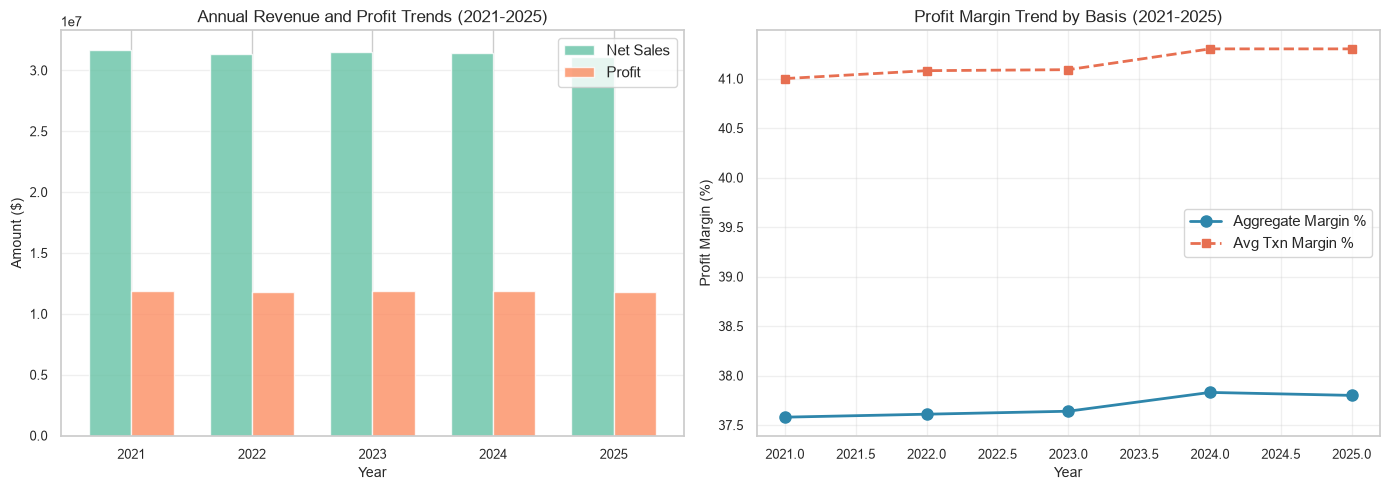

In [7]:
# Visualization: Annual trends
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Net Sales and Profit by Year
ax1 = axes[0]
x_years = yearly_metrics.index
width = 0.35
x_pos = np.arange(len(x_years))

bars1 = ax1.bar(x_pos - width/2, yearly_metrics['Net Sales'], width, label='Net Sales', alpha=0.8)
bars2 = ax1.bar(x_pos + width/2, yearly_metrics['Profit'], width, label='Profit', alpha=0.8)

ax1.set_xlabel('Year')
ax1.set_ylabel('Amount ($)')
ax1.set_title('Annual Revenue and Profit Trends (2021-2025)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(x_years)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Right: Profit margin by year, both bases
ax2 = axes[1]
ax2.plot(yearly_metrics.index, yearly_metrics['Aggregate Margin %'],
         marker='o', linewidth=2, markersize=8, color='#2E86AB', label='Aggregate Margin %')
ax2.plot(yearly_metrics.index, yearly_metrics['Avg Txn Margin %'],
         marker='s', linewidth=2, markersize=6, color='#E76F51',
         linestyle='--', label='Avg Txn Margin %')
ax2.set_xlabel('Year')
ax2.set_ylabel('Profit Margin (%)')
ax2.set_title('Profit Margin Trend by Basis (2021-2025)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


In [8]:
# Year-over-Year Growth Analysis
yearly_metrics = df.groupby('order_year').agg({
    'order_id': 'count',
    'customer_id': 'nunique',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)

yearly_metrics.columns = ['Transactions', 'Unique Customers', 'Net Sales', 'Profit', 'Avg Txn Margin %']
yearly_metrics['Aggregate Margin %'] = (yearly_metrics['Profit'] / yearly_metrics['Net Sales'] * 100).round(2)

# Calculate YoY growth rates
yearly_metrics['Revenue Growth %'] = (yearly_metrics['Net Sales'].pct_change() * 100).round(2)
yearly_metrics['Profit Growth %'] = (yearly_metrics['Profit'].pct_change() * 100).round(2)
yearly_metrics['Transaction Growth %'] = (yearly_metrics['Transactions'].pct_change() * 100).round(2)

print("Annual Performance with Year-over-Year Growth:")
print(yearly_metrics)

# Check for partial year data
latest_year = int(df['order_year'].max())
latest_year_days = df[df['order_year'] == latest_year]['order_date'].nunique()
print(f"\n[INFO] Year {latest_year} has {latest_year_days} days of data")
if latest_year_days < 300:
    print(f"[WARNING] Year {latest_year} appears to be a partial year - growth rates may not be comparable")
else:
    print("[INFO] All years are complete; YoY growth rates are comparable.")


Annual Performance with Year-over-Year Growth:
            Transactions  Unique Customers     Net Sales        Profit  \
order_year                                                               
2021               27554             16635 31,690,972.96 11,909,436.79   
2022               27564             16793 31,331,038.21 11,784,396.53   
2023               27632             16767 31,532,248.71 11,869,282.44   
2024               27768             16818 31,462,212.82 11,903,089.81   
2025               27598             16717 31,126,741.36 11,766,099.78   

            Avg Txn Margin %  Aggregate Margin %  Revenue Growth %  \
order_year                                                           
2021                   41.00               37.58               NaN   
2022                   41.08               37.61             -1.14   
2023                   41.09               37.64              0.64   
2024                   41.30               37.83             -0.22   
2025          

In [9]:
# Monthly aggregation across all years
monthly_metrics = df.groupby('order_month').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)

monthly_metrics.columns = ['Transactions', 'Net Sales', 'Profit', 'Avg Txn Margin %']
monthly_metrics['Aggregate Margin %'] = (monthly_metrics['Profit'] / monthly_metrics['Net Sales'] * 100).round(2)

print("\nMonthly Seasonality (Aggregated Across All Years):")
print(monthly_metrics)



Monthly Seasonality (Aggregated Across All Years):
             Transactions     Net Sales       Profit  Avg Txn Margin %  \
order_month                                                              
1                    9693 10,866,360.24 4,657,040.59             45.97   
2                    8027  8,961,197.64 3,823,851.13             45.73   
3                   10822 12,125,745.35 5,166,136.73             45.63   
4                   10120 11,216,745.07 4,824,511.96             45.98   
5                   10238 11,193,399.59 4,807,575.70             46.04   
6                   10880 11,949,870.45 5,130,130.10             45.95   
7                   10207 12,482,977.37 4,271,367.88             38.12   
8                   12064 13,356,216.71 5,722,366.14             45.90   
9                   10855 12,248,299.05 4,889,730.87             43.12   
10                  11582 12,940,914.16 5,528,485.35             45.85   
11                  16061 19,107,451.30 4,947,766.61        

### Analisis Pola Musiman (Seasonality)

Penggabungan data lintas tahun (2021-2025) mengungkapkan pola berikut:

1. **Bulan normal (Januari-Juni, Agustus, Oktober):** rata-rata margin transaksi sekitar 46%
   (margin agregat 42,6%-43,0%), dengan rata-rata diskon bulanan sekitar 9,7%.
2. **Juli dan September:** Juli memiliki rata-rata diskon 20,0% dan margin agregat 34,22%;
   September memiliki rata-rata diskon 13,7% dan margin agregat 39,92%. Keduanya adalah periode
   promo di tengah tahun dan tetap di bawah kedalaman diskon Q4.
3. **Fase akhir tahun (November-Desember):** volume dan omzet naik signifikan (Desember
   $20,7 juta), tetapi margin turun. Rata-rata diskon naik ke 27,6% dan rata-rata margin
   transaksi turun ke 29,7% (margin agregat 25,9%-26,4%). Margin agregat Januari-Oktober
   adalah 41,6%.

**Insight Bisnis (deskriptif):** periode promo, terutama Q4, menaikkan volume penjualan
sekaligus menurunkan margin. Pola ini berkaitan dengan kedalaman diskon dan konsisten dengan
anomali "High Revenue, Low Margin". Analisis ini tidak membuktikan sebab-akibat: kedalaman
diskon, bauran produk, dan perilaku pelanggan dapat saling memengaruhi dan belum dipisahkan.


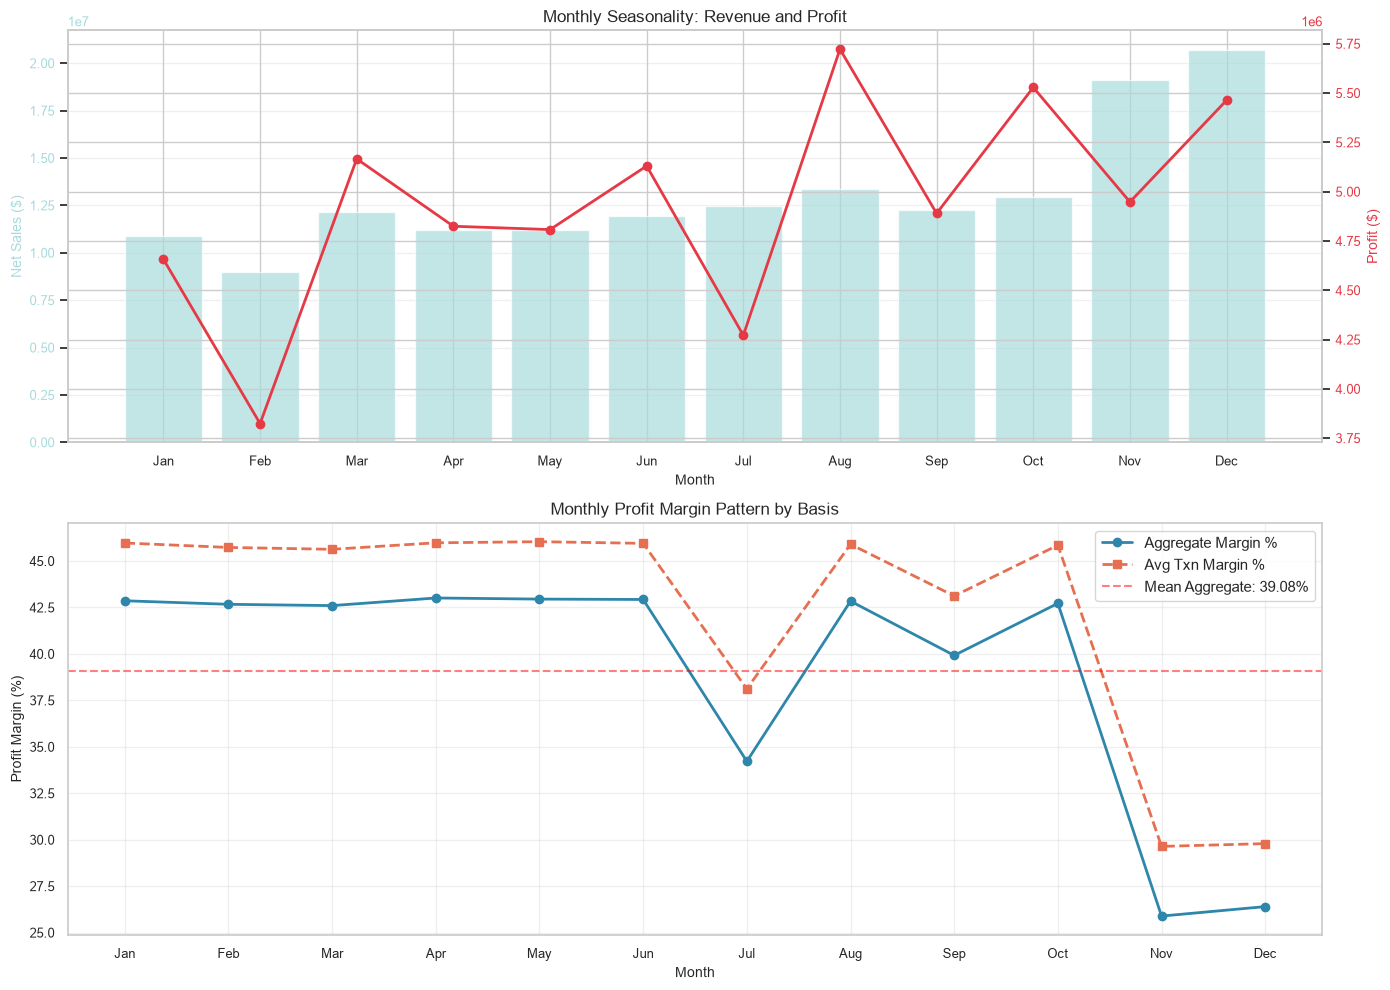

In [10]:
# Visualization: Monthly seasonality
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Top: Net Sales and Profit by Month
ax1 = axes[0]
ax1_twin = ax1.twinx()

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
x_pos = np.arange(len(months))

bars = ax1.bar(x_pos, monthly_metrics['Net Sales'], alpha=0.7, label='Net Sales', color='#A8DADC')
line = ax1_twin.plot(x_pos, monthly_metrics['Profit'], marker='o', linewidth=2,
                     markersize=6, color='#E63946', label='Profit')

ax1.set_xlabel('Month')
ax1.set_ylabel('Net Sales ($)', color='#A8DADC')
ax1_twin.set_ylabel('Profit ($)', color='#E63946')
ax1.set_title('Monthly Seasonality: Revenue and Profit')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(months)
ax1.tick_params(axis='y', labelcolor='#A8DADC')
ax1_twin.tick_params(axis='y', labelcolor='#E63946')
ax1.grid(axis='y', alpha=0.3)

# Bottom: Profit margin by month, both bases
ax2 = axes[1]
ax2.plot(x_pos, monthly_metrics['Aggregate Margin %'], marker='o', linewidth=2,
         markersize=6, color='#2E86AB', label='Aggregate Margin %')
ax2.plot(x_pos, monthly_metrics['Avg Txn Margin %'], marker='s', linewidth=2,
         markersize=6, color='#E76F51', linestyle='--', label='Avg Txn Margin %')
ax2.set_xlabel('Month')
ax2.set_ylabel('Profit Margin (%)')
ax2.set_title('Monthly Profit Margin Pattern by Basis')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(months)
ax2.axhline(y=monthly_metrics['Aggregate Margin %'].mean(), color='red',
            linestyle='--', alpha=0.5, label=f"Mean Aggregate: {monthly_metrics['Aggregate Margin %'].mean():.2f}%")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:
# Quarterly analysis
quarterly_metrics = df.groupby('order_quarter').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)

quarterly_metrics.columns = ['Transactions', 'Net Sales', 'Profit', 'Avg Txn Margin %']
quarterly_metrics['Aggregate Margin %'] = (quarterly_metrics['Profit'] / quarterly_metrics['Net Sales'] * 100).round(2)

print("\nQuarterly Performance (Aggregated Across All Years):")
print(quarterly_metrics)



Quarterly Performance (Aggregated Across All Years):
               Transactions     Net Sales        Profit  Avg Txn Margin %  \
order_quarter                                                               
1                     28542 31,953,303.23 13,647,028.45             45.77   
2                     31238 34,360,015.11 14,762,217.76             45.99   
3                     33126 38,087,493.13 14,883,464.89             42.59   
4                     45210 52,742,402.59 15,939,594.25             33.85   

               Aggregate Margin %  
order_quarter                      
1                           42.71  
2                           42.96  
3                           39.08  
4                           30.22  


In [12]:
# Weekday vs Weekend analysis
weekend_metrics = df.groupby('is_weekend').agg({
    'order_id': 'count',
    'net_sales': ['sum', 'mean'],
    'profit': ['sum', 'mean'],
    'profit_margin_percentage': 'mean'
}).round(2)

weekend_metrics.columns = ['Transactions', 'Total Net Sales', 'Avg Net Sales',
                           'Total Profit', 'Avg Profit', 'Avg Txn Margin %']
weekend_metrics['Aggregate Margin %'] = (weekend_metrics['Total Profit'] / weekend_metrics['Total Net Sales'] * 100).round(2)
weekend_metrics.index = ['Weekday', 'Weekend']

print("\nWeekday vs Weekend Comparison:")
print(weekend_metrics)



Weekday vs Weekend Comparison:
         Transactions  Total Net Sales  Avg Net Sales  Total Profit  \
Weekday         98686   112,001,051.82       1,134.92 42,235,680.43   
Weekend         39430    45,142,162.24       1,144.87 16,996,624.92   

         Avg Profit  Avg Txn Margin %  Aggregate Margin %  
Weekday      427.98             41.15               37.71  
Weekend      431.06             41.16               37.65  


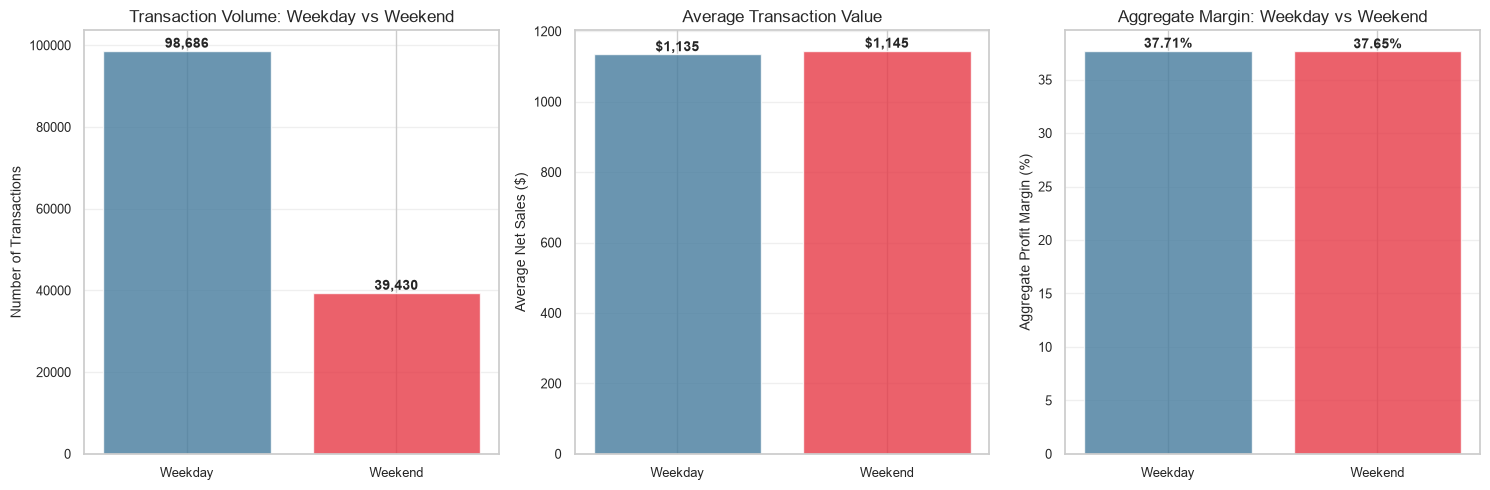

In [13]:
# Visualization: Weekday vs Weekend
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

categories = ['Weekday', 'Weekend']

# Left: Transaction Volume
ax1 = axes[0]
bars = ax1.bar(categories, weekend_metrics['Transactions'], alpha=0.8, color=['#457B9D', '#E63946'])
ax1.set_ylabel('Number of Transactions')
ax1.set_title('Transaction Volume: Weekday vs Weekend')
ax1.grid(axis='y', alpha=0.3)
for i, v in enumerate(weekend_metrics['Transactions']):
    ax1.text(i, v, f'{v:,.0f}', ha='center', va='bottom', fontweight='bold')

# Middle: Average Transaction Value
ax2 = axes[1]
bars = ax2.bar(categories, weekend_metrics['Avg Net Sales'], alpha=0.8, color=['#457B9D', '#E63946'])
ax2.set_ylabel('Average Net Sales ($)')
ax2.set_title('Average Transaction Value')
ax2.grid(axis='y', alpha=0.3)
for i, v in enumerate(weekend_metrics['Avg Net Sales']):
    ax2.text(i, v, f'${v:,.0f}', ha='center', va='bottom', fontweight='bold')

# Right: Aggregate Profit Margin
ax3 = axes[2]
bars = ax3.bar(categories, weekend_metrics['Aggregate Margin %'], alpha=0.8, color=['#457B9D', '#E63946'])
ax3.set_ylabel('Aggregate Profit Margin (%)')
ax3.set_title('Aggregate Margin: Weekday vs Weekend')
ax3.grid(axis='y', alpha=0.3)
for i, v in enumerate(weekend_metrics['Aggregate Margin %']):
    ax3.text(i, v, f'{v:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


## Fase 3: Diskon vs. Profitabilitas

### Pertanyaan Bisnis Kritis

Pada bracket diskon mana margin profit turun paling tajam?

### Pendekatan Analisis

1. **Analisis korelasi:** mengkaji hubungan antara discount_rate dan profit_margin_percentage
2. **Visualisasi scatter:** hexbin plot untuk pola kepadatan 138 ribu transaksi
3. **Segmentasi bracket:** 0% (tanpa diskon), 1-10%, 11-20%, 21-30%, 30%+
4. **Perbandingan dua basis margin:** rata-rata margin transaksi dan margin agregat per bracket
5. **Analisis deskriptif:** melihat bracket tempat penurunan margin antar bracket paling besar

### Batas Kesimpulan

Hasil fase ini bersifat deskriptif. Analisis ini tidak menetapkan batas diskon optimal dan
tidak mengklaim hubungan sebab-akibat, karena kedalaman diskon berkorelasi dengan ukuran
keranjang dan bauran produk.


In [14]:
# Correlation between discount rate and profit margin
correlation = df[['discount_rate', 'profit_margin_percentage']].corr().iloc[0, 1]

print(f"Correlation between Discount Rate and Profit Margin: {correlation:.4f}")
print("\nBasic Statistics:")
print(df[['discount_rate', 'profit_margin_percentage']].describe())

Correlation between Discount Rate and Profit Margin: -0.7148

Basic Statistics:
       discount_rate  profit_margin_percentage
count     138,116.00                138,116.00
mean           15.12                     41.16
std            12.29                     14.88
min             0.00                    -71.98
25%             6.54                     34.12
50%            12.75                     43.30
75%            20.60                     51.04
max            60.02                     74.93


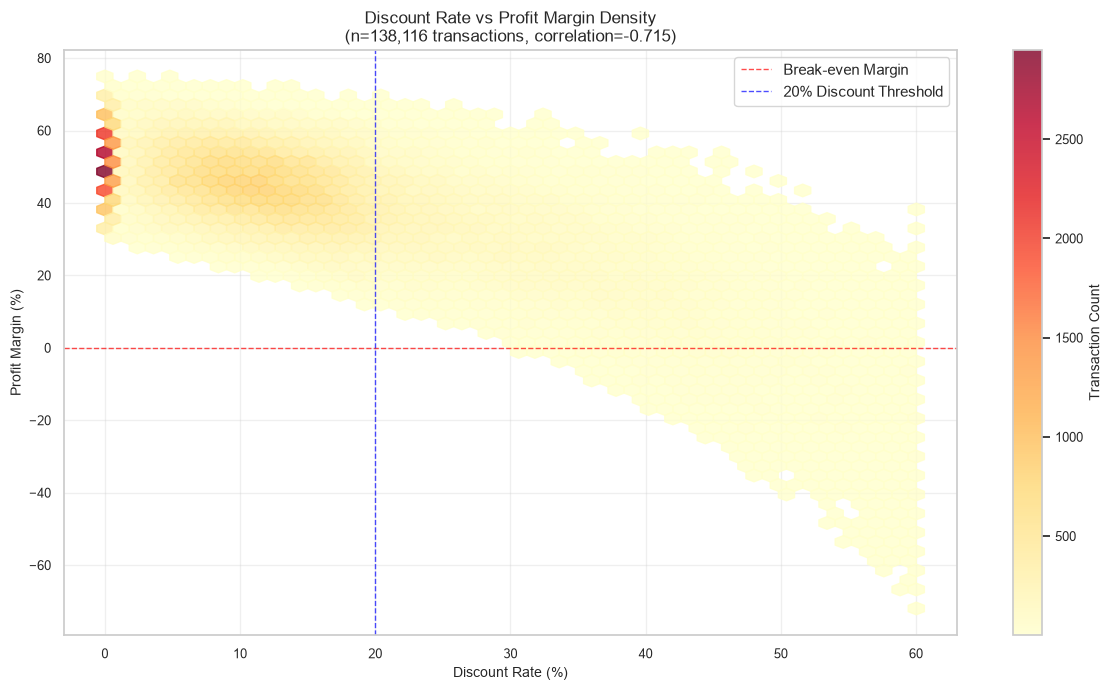

In [15]:
# Hexbin plot: Discount Rate vs Profit Margin
fig, ax = plt.subplots(figsize=(12, 7))

hexbin = ax.hexbin(df['discount_rate'], df['profit_margin_percentage'], 
                   gridsize=50, cmap='YlOrRd', mincnt=1, alpha=0.8)

ax.set_xlabel('Discount Rate (%)')
ax.set_ylabel('Profit Margin (%)')
ax.set_title(f'Discount Rate vs Profit Margin Density\n(n={len(df):,} transactions, correlation={correlation:.3f})')
ax.grid(True, alpha=0.3)

# Add reference lines
ax.axhline(y=0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Break-even Margin')
ax.axvline(x=20, color='blue', linestyle='--', linewidth=1, alpha=0.7, label='20% Discount Threshold')

ax.legend()
cbar = plt.colorbar(hexbin, ax=ax)
cbar.set_label('Transaction Count')

plt.tight_layout()
plt.show()

In [16]:
# Create discount brackets
def categorize_discount(rate):
    if rate == 0:
        return '0% (No Discount)'
    elif rate <= 10:
        return '1-10%'
    elif rate <= 20:
        return '11-20%'
    elif rate <= 30:
        return '21-30%'
    else:
        return '30%+'

df['discount_bracket'] = df['discount_rate'].apply(categorize_discount)

# Aggregate by discount bracket
discount_analysis = df.groupby('discount_bracket').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)

discount_analysis.columns = ['Transactions', 'Total Net Sales', 'Total Profit', 'Avg Txn Margin %']
discount_analysis['Aggregate Margin %'] = (discount_analysis['Total Profit'] / discount_analysis['Total Net Sales'] * 100).round(2)
discount_analysis['Profit per Transaction'] = (discount_analysis['Total Profit'] / discount_analysis['Transactions']).round(2)

# Order by discount bracket
bracket_order = ['0% (No Discount)', '1-10%', '11-20%', '21-30%', '30%+']
discount_analysis = discount_analysis.reindex(bracket_order)

print("Discount Bracket Analysis:")
print(discount_analysis)


Discount Bracket Analysis:
                  Transactions  Total Net Sales  Total Profit  \
discount_bracket                                                
0% (No Discount)         17864    21,770,139.34 10,538,011.45   
1-10%                    35031    39,340,499.03 17,601,245.35   
11-20%                   49198    52,820,114.92 21,062,207.54   
21-30%                   17729    21,188,389.22  6,689,904.26   
30%+                     18294    22,024,071.55  3,340,936.75   

                  Avg Txn Margin %  Aggregate Margin %  Profit per Transaction  
discount_bracket                                                                
0% (No Discount)             51.30               48.41                  589.90  
1-10%                        48.06               44.74                  502.45  
11-20%                       43.11               39.88                  428.11  
21-30%                       35.61               31.57                  377.34  
30%+                         18

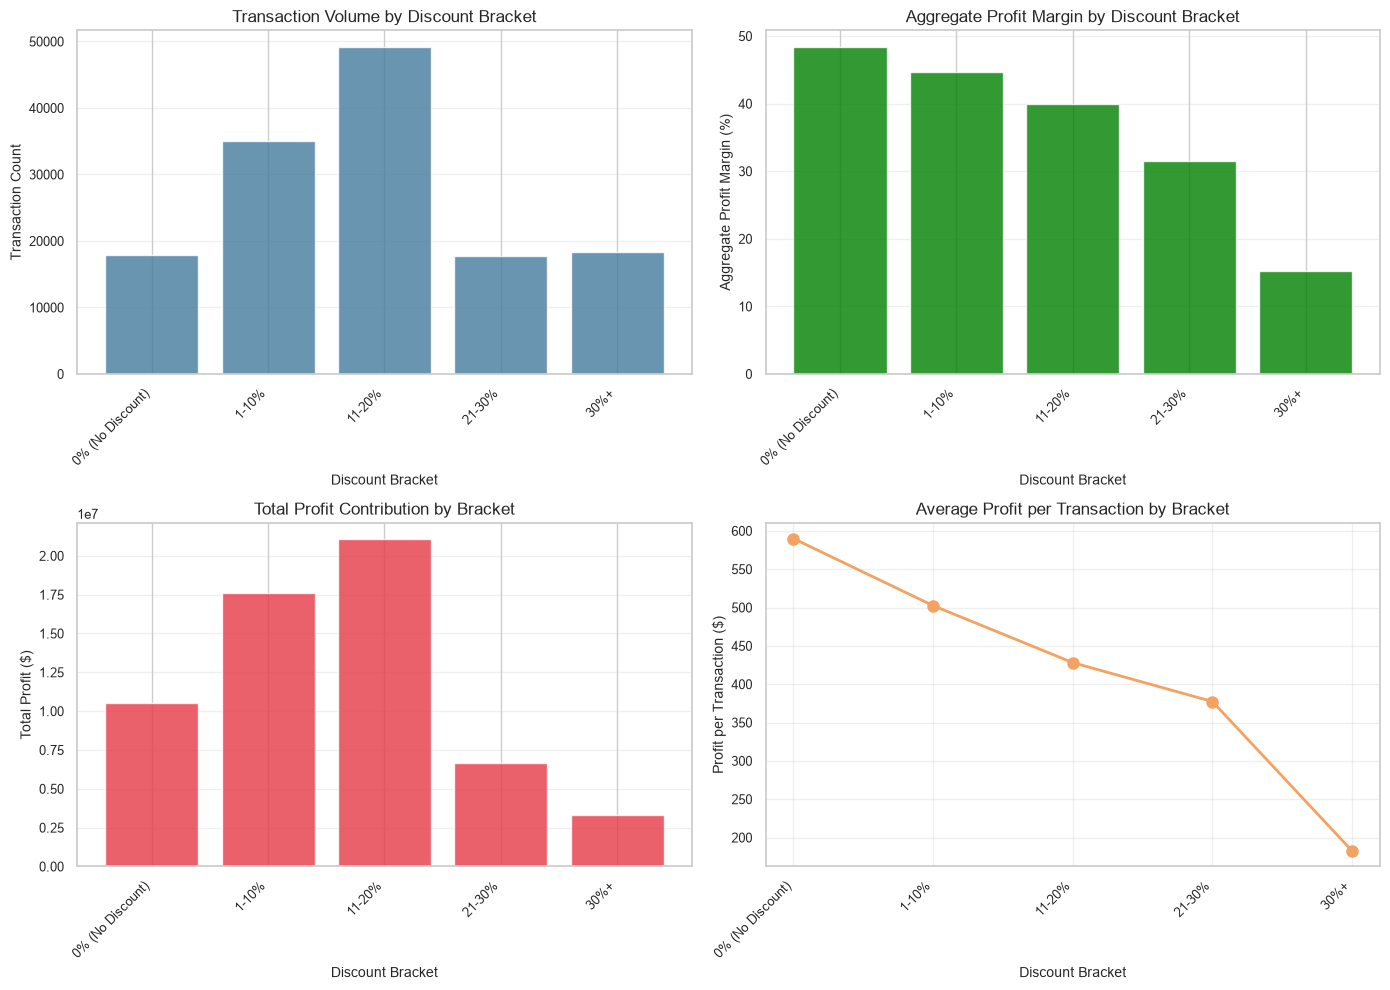

In [17]:
# Visualization: Discount Bracket Impact
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

brackets = discount_analysis.index

# Top-left: Transaction Count by Bracket
ax1 = axes[0, 0]
bars = ax1.bar(range(len(brackets)), discount_analysis['Transactions'], alpha=0.8, color='#457B9D')
ax1.set_xlabel('Discount Bracket')
ax1.set_ylabel('Transaction Count')
ax1.set_title('Transaction Volume by Discount Bracket')
ax1.set_xticks(range(len(brackets)))
ax1.set_xticklabels(brackets, rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)

# Top-right: Aggregate Profit Margin by Bracket
ax2 = axes[0, 1]
colors = ['green' if x > 0 else 'red' for x in discount_analysis['Aggregate Margin %']]
bars = ax2.bar(range(len(brackets)), discount_analysis['Aggregate Margin %'], alpha=0.8, color=colors)
ax2.set_xlabel('Discount Bracket')
ax2.set_ylabel('Aggregate Profit Margin (%)')
ax2.set_title('Aggregate Profit Margin by Discount Bracket')
ax2.set_xticks(range(len(brackets)))
ax2.set_xticklabels(brackets, rotation=45, ha='right')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax2.grid(axis='y', alpha=0.3)

# Bottom-left: Total Profit by Bracket
ax3 = axes[1, 0]
bars = ax3.bar(range(len(brackets)), discount_analysis['Total Profit'], alpha=0.8, color='#E63946')
ax3.set_xlabel('Discount Bracket')
ax3.set_ylabel('Total Profit ($)')
ax3.set_title('Total Profit Contribution by Bracket')
ax3.set_xticks(range(len(brackets)))
ax3.set_xticklabels(brackets, rotation=45, ha='right')
ax3.grid(axis='y', alpha=0.3)

# Bottom-right: Profit per Transaction
ax4 = axes[1, 1]
line = ax4.plot(range(len(brackets)), discount_analysis['Profit per Transaction'],
                marker='o', linewidth=2, markersize=8, color='#F4A261')
ax4.set_xlabel('Discount Bracket')
ax4.set_ylabel('Profit per Transaction ($)')
ax4.set_title('Average Profit per Transaction by Bracket')
ax4.set_xticks(range(len(brackets)))
ax4.set_xticklabels(brackets, rotation=45, ha='right')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [18]:
# Aggregate Margin vs Average Transaction Margin Comparison
print("\nMargin Metric Comparison by Discount Bracket:")
print("=" * 70)

for bracket in discount_analysis.index:
    avg_txn_margin = discount_analysis.loc[bracket, 'Avg Txn Margin %']
    agg_margin = discount_analysis.loc[bracket, 'Aggregate Margin %']

    print(f"\n{bracket}:")
    print(f"  Average Transaction Margin: {avg_txn_margin:.2f}%")
    print(f"  Aggregate Margin:          {agg_margin:.2f}%")
    print(f"  Difference:                {avg_txn_margin - agg_margin:.2f}pp")

print("\n[INFO] Average transaction margin = mean of per-transaction margins")
print("[INFO] Aggregate margin = total profit / total net sales")
print("[INFO] Aggregate margin is the primary margin metric; the average transaction margin is a secondary, differently labelled metric.")



Margin Metric Comparison by Discount Bracket:

0% (No Discount):
  Average Transaction Margin: 51.30%
  Aggregate Margin:          48.41%
  Difference:                2.89pp

1-10%:
  Average Transaction Margin: 48.06%
  Aggregate Margin:          44.74%
  Difference:                3.32pp

11-20%:
  Average Transaction Margin: 43.11%
  Aggregate Margin:          39.88%
  Difference:                3.23pp

21-30%:
  Average Transaction Margin: 35.61%
  Aggregate Margin:          31.57%
  Difference:                4.04pp

30%+:
  Average Transaction Margin: 18.13%
  Aggregate Margin:          15.17%
  Difference:                2.96pp

[INFO] Average transaction margin = mean of per-transaction margins
[INFO] Aggregate margin = total profit / total net sales
[INFO] Aggregate margin is the primary margin metric; the average transaction margin is a secondary, differently labelled metric.


In [19]:
# Margin behaviour across discount brackets (descriptive, not causal)
m_0 = df[df['discount_rate'] == 0]['profit_margin_percentage'].mean()
m_1_10 = df[(df['discount_rate'] > 0) & (df['discount_rate'] <= 10)]['profit_margin_percentage'].mean()
m_11_20 = df[(df['discount_rate'] > 10) & (df['discount_rate'] <= 20)]['profit_margin_percentage'].mean()
m_21_30 = df[(df['discount_rate'] > 20) & (df['discount_rate'] <= 30)]['profit_margin_percentage'].mean()
m_30plus = df[df['discount_rate'] > 30]['profit_margin_percentage'].mean()

# Profit per transaction
ppt_20 = df[df['discount_rate'] <= 20]['profit'].mean()
ppt_30plus = df[df['discount_rate'] > 30]['profit'].mean()
ppt_reduction_pct = (ppt_20 - ppt_30plus) / ppt_20 * 100

# Basket size (confound check)
basket_0 = df[df['discount_rate'] == 0]['quantity'].mean()
basket_30plus = df[df['discount_rate'] > 30]['quantity'].mean()

# Counterfactual simulation: illustrative only, explicit assumptions
high_discount_txns = len(df[df['discount_rate'] > 30])
potential_profit_30 = df[df['discount_rate'] > 30]['net_sales'].sum() * m_21_30 / 100
profit_recovery = (potential_profit_30 - df[df['discount_rate'] > 30]['profit'].sum()) * 0.5 / 1e6

print(f"""
INSIGHT #2: Pola Margin pada Bracket Diskon (Deskriptif)

RATA-RATA MARGIN TRANSAKSI PER BRACKET:
- Diskon 0%:      {m_0:.1f}%
- Diskon 1-10%:   {m_1_10:.1f}%
- Diskon 11-20%:  {m_11_20:.1f}%
- Diskon 21-30%:  {m_21_30:.1f}%
- Diskon 30%+:    {m_30plus:.1f}%

LANGKAH ANTAR BRACKET (poin persentase):
- 0% -> 1-10%:      {m_1_10 - m_0:.1f} pp
- 1-10% -> 11-20%:  {m_11_20 - m_1_10:.1f} pp
- 11-20% -> 21-30%: {m_21_30 - m_11_20:.1f} pp
- 21-30% -> 30%+:   {m_30plus - m_21_30:.1f} pp  (langkah terbesar)
- Transaksi diskon 30%+ menghasilkan profit per transaksi {ppt_reduction_pct:.0f}% lebih rendah
  dari transaksi diskon <=20%.

PEMBANDING BASKET (confound):
- Rata-rata quantity: diskon 0% = {basket_0:.2f}, diskon 30%+ = {basket_30plus:.2f}
- Order berdiskon dalam cenderung berkeranjang lebih besar, sehingga selisih margin antar
  bracket tidak sepenuhnya efek diskon.

SIMULASI KONTAKTUAL - ILUSTRATIF, BUKAN PRAKIRAAN:
- Asumsi eksplisit: 50% transaksi diskon 30%+ dihilangkan dan net_sales-nya dijalankan pada
  margin level 21-30%. Respons permintaan, biaya tetap, dan kanibalisasi diabaikan.
- Hasil: +${profit_recovery:.1f}M "profit recovery" ({high_discount_txns:,} transaksi). Angka ini
  bukan target dan bukan forecast.

REKOMENDASI (perlu validasi, belum ditetapkan):
- Tinjau kebijakan diskon 30%+ per kategori.
- Uji dampak permintaan sebelum menetapkan batas diskon. Analisis ini tidak membuktikan
  sebab-akibat dan tidak menetapkan angka diskon optimal.
""")



INSIGHT #2: Pola Margin pada Bracket Diskon (Deskriptif)

RATA-RATA MARGIN TRANSAKSI PER BRACKET:
- Diskon 0%:      51.3%
- Diskon 1-10%:   48.1%
- Diskon 11-20%:  43.1%
- Diskon 21-30%:  35.6%
- Diskon 30%+:    18.1%

LANGKAH ANTAR BRACKET (poin persentase):
- 0% -> 1-10%:      -3.2 pp
- 1-10% -> 11-20%:  -4.9 pp
- 11-20% -> 21-30%: -7.5 pp
- 21-30% -> 30%+:   -17.5 pp  (langkah terbesar)
- Transaksi diskon 30%+ menghasilkan profit per transaksi 62% lebih rendah
  dari transaksi diskon <=20%.

PEMBANDING BASKET (confound):
- Rata-rata quantity: diskon 0% = 4.98, diskon 30%+ = 7.94
- Order berdiskon dalam cenderung berkeranjang lebih besar, sehingga selisih margin antar
  bracket tidak sepenuhnya efek diskon.

SIMULASI KONTAKTUAL - ILUSTRATIF, BUKAN PRAKIRAAN:
- Asumsi eksplisit: 50% transaksi diskon 30%+ dihilangkan dan net_sales-nya dijalankan pada
  margin level 21-30%. Respons permintaan, biaya tetap, dan kanibalisasi diabaikan.
- Hasil: +$2.3M "profit recovery" (18,294 transaksi)

## Fase 4: Anomali Revenue Tinggi, Margin Rendah

### Pernyataan Masalah

Fase profiling mengidentifikasi 12.855 transaksi dengan revenue tinggi namun margin rendah
(aturan inklusif). Anomali ini merupakan perhatian strategis: penjualan bervolume besar namun
margin rendah.

### Definisi Anomali

- **Revenue Tinggi:** `net_sales` pada atau di atas persentil ke-75
- **Margin Rendah:** `profit_margin_percentage` pada atau di bawah persentil ke-25
- **Operator:** inklusif (`>=` dan `<=`) sebagai aturan default MVP. Varian ketat (`>` dan `<`)
  menghasilkan 12.855 transaksi juga; tidak ada transaksi yang tepat berada di ambang di antara
  kedua aturan.

### Dimensi Investigasi

Tabel penjualan tidak memiliki kolom `product_id`; relasi produk tersedia di `order_items.csv`
tetapi belum direkonsiliasi dengan tabel penjualan. Karena itu analisis berfokus pada dimensi
operasional dan analisis level produk ditunda:

1. **Region:** pola geografis dalam transaksi anomali
2. **Sales Channel:** Mobile App, Website, Social Media, dan Marketplace
3. **Marketing Channel:** sumber akuisisi dengan tingkat anomali tinggi

### Kepentingan Strategis

Mengidentifikasi pola ini memungkinkan intervensi terarah. Namun setiap intervensi harus diuji
dampaknya terlebih dahulu; analisis ini deskriptif dan tidak menguji sebab-akibat.


In [20]:
# Anomaly rule (MVP default: inclusive operators)
high_revenue_threshold = df['net_sales'].quantile(0.75)
low_margin_threshold = df['profit_margin_percentage'].quantile(0.25)

print("Anomaly Rule (MVP default: inclusive):")
print("  is_anomaly = (net_sales >= 75th percentile) AND (profit_margin_percentage <= 25th percentile)")
print(f"  High Revenue (75th percentile): ${high_revenue_threshold:,.2f}")
print(f"  Low Margin (25th percentile): {low_margin_threshold:.2f}%")

# Filter anomalous transactions
df['is_anomaly'] = ((df['net_sales'] >= high_revenue_threshold) &
                     (df['profit_margin_percentage'] <= low_margin_threshold))

anomaly_count = int(df['is_anomaly'].sum())
anomaly_pct = (anomaly_count / len(df)) * 100

# Strict variant, kept only to document that the two rules differ by threshold tie-breaking
strict_count = int(((df['net_sales'] > high_revenue_threshold) &
                    (df['profit_margin_percentage'] < low_margin_threshold)).sum())

print(f"\nAnomalous Transactions: {anomaly_count:,} ({anomaly_pct:.2f}%)")
print(f"  [INFO] Strict variant (> / <) gives {strict_count:,}; tie-breaking difference = {anomaly_count - strict_count:,} transaction(s).")

# Separate normal and anomalous data
df_normal = df[~df['is_anomaly']].copy()
df_anomaly = df[df['is_anomaly']].copy()

print(f"Normal Transactions: {len(df_normal):,}")
print(f"Anomalous Transactions: {len(df_anomaly):,}")


Anomaly Rule (MVP default: inclusive):
  is_anomaly = (net_sales >= 75th percentile) AND (profit_margin_percentage <= 25th percentile)
  High Revenue (75th percentile): $1,552.32
  Low Margin (25th percentile): 34.12%

Anomalous Transactions: 12,855 (9.31%)
  [INFO] Strict variant (> / <) gives 12,855; tie-breaking difference = 0 transaction(s).
Normal Transactions: 125,261
Anomalous Transactions: 12,855


In [21]:
# Anomaly analysis by Sales Channel
channel_anomaly = pd.DataFrame({
    'Total': df.groupby('sales_channel').size(),
    'Anomaly': df_anomaly.groupby('sales_channel').size(),
    'Normal': df_normal.groupby('sales_channel').size()
})

channel_anomaly['Anomaly %'] = (channel_anomaly['Anomaly'] / channel_anomaly['Total'] * 100).round(2)
channel_anomaly = channel_anomaly.sort_values('Anomaly %', ascending=False)

print("\nAnomaly Distribution by Sales Channel:")
print(channel_anomaly)


Anomaly Distribution by Sales Channel:
               Total  Anomaly  Normal  Anomaly %
sales_channel                                   
Marketplace    20698     2002   18696       9.67
Mobile App     55318     5164   50154       9.34
Social Media   13863     1275   12588       9.20
Website        48237     4414   43823       9.15


In [22]:
# Anomaly analysis by Region
region_anomaly = pd.DataFrame({
    'Total': df.groupby('region').size(),
    'Anomaly': df_anomaly.groupby('region').size(),
    'Normal': df_normal.groupby('region').size()
})

region_anomaly['Anomaly %'] = (region_anomaly['Anomaly'] / region_anomaly['Total'] * 100).round(2)
region_anomaly = region_anomaly.sort_values('Anomaly %', ascending=False)

print("\nAnomaly Distribution by Region:")
print(region_anomaly)


Anomaly Distribution by Region:
         Total  Anomaly  Normal  Anomaly %
region                                    
South    43990     4172   39818       9.48
Central  29627     2749   26878       9.28
West     26273     2439   23834       9.28
East     21602     2001   19601       9.26
North    16624     1494   15130       8.99


In [23]:
# Anomaly analysis by Marketing Channel
marketing_anomaly = pd.DataFrame({
    'Total': df.groupby('marketing_channel').size(),
    'Anomaly': df_anomaly.groupby('marketing_channel').size(),
    'Normal': df_normal.groupby('marketing_channel').size()
})

marketing_anomaly['Anomaly %'] = (marketing_anomaly['Anomaly'] / marketing_anomaly['Total'] * 100).round(2)
marketing_anomaly = marketing_anomaly.sort_values('Anomaly %', ascending=False)

print("\nAnomaly Distribution by Marketing Channel:")
print(marketing_anomaly)


Anomaly Distribution by Marketing Channel:
                   Total  Anomaly  Normal  Anomaly %
marketing_channel                                   
Email Marketing    11218     1108   10110       9.88
Google Ads         20633     1974   18659       9.57
Organic Search     27742     2624   25118       9.46
YouTube             4080      385    3695       9.44
Instagram          13801     1279   12522       9.27
Affiliate           6848      625    6223       9.13
Facebook Ads       16651     1515   15136       9.10
Referral           11191     1016   10175       9.08
Direct             20515     1844   18671       8.99
TikTok              5437      485    4952       8.92


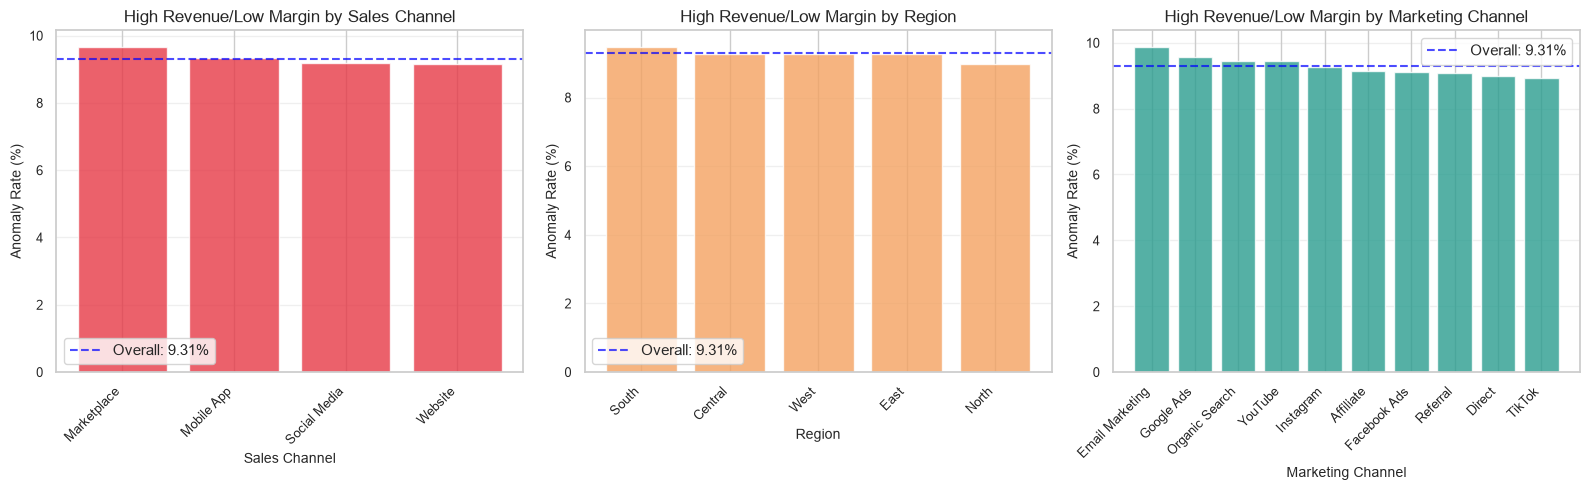

In [24]:
# Visualization: Anomaly by Operational Dimensions
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Left: Sales Channel
ax1 = axes[0]
x_pos = np.arange(len(channel_anomaly))
bars = ax1.bar(x_pos, channel_anomaly['Anomaly %'], alpha=0.8, color='#E63946')
ax1.set_xlabel('Sales Channel')
ax1.set_ylabel('Anomaly Rate (%)')
ax1.set_title('High Revenue/Low Margin by Sales Channel')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(channel_anomaly.index, rotation=45, ha='right')
ax1.axhline(y=anomaly_pct, color='blue', linestyle='--', alpha=0.7, label=f'Overall: {anomaly_pct:.2f}%')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Middle: Region
ax2 = axes[1]
x_pos = np.arange(len(region_anomaly))
bars = ax2.bar(x_pos, region_anomaly['Anomaly %'], alpha=0.8, color='#F4A261')
ax2.set_xlabel('Region')
ax2.set_ylabel('Anomaly Rate (%)')
ax2.set_title('High Revenue/Low Margin by Region')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(region_anomaly.index, rotation=45, ha='right')
ax2.axhline(y=anomaly_pct, color='blue', linestyle='--', alpha=0.7, label=f'Overall: {anomaly_pct:.2f}%')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Right: Marketing Channel
ax3 = axes[2]
x_pos = np.arange(len(marketing_anomaly))
bars = ax3.bar(x_pos, marketing_anomaly['Anomaly %'], alpha=0.8, color='#2A9D8F')
ax3.set_xlabel('Marketing Channel')
ax3.set_ylabel('Anomaly Rate (%)')
ax3.set_title('High Revenue/Low Margin by Marketing Channel')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(marketing_anomaly.index, rotation=45, ha='right')
ax3.axhline(y=anomaly_pct, color='blue', linestyle='--', alpha=0.7, label=f'Overall: {anomaly_pct:.2f}%')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Fase 5: Intelijen Segmen Pelanggan

### Fokus Strategis

Mengevaluasi profitabilitas segmen pelanggan untuk mengoptimalkan alokasi pemasaran dan strategi retensi.

### Komponen Analisis

1. **Profitabilitas Segmen:** kontribusi profit total, margin agregat, rata-rata margin transaksi, dan profit per pelanggan (Consumer, Premium, VIP, Business)
2. **Kinerja Channel Akuisisi:** channel pemasaran mana yang menghasilkan profit per transaksi tertinggi untuk setiap segmen
3. **Perbandingan Pembelian Berulang:** selisih margin transaksi antara pelanggan pertama kali dan pelanggan berulang. Sampel pelanggan pertama kali sangat kecil (334 transaksi), sehingga hasil dibaca sebagai keterbatasan, bukan temuan.
4. **Lifetime Value:** angka CLV pada dataset **belum tervalidasi** dan tidak dipakai sebagai KPI MVP (lihat Catatan Keterbatasan).

### Catatan Keterbatasan

- Kolom `is_repeat_customer` bernilai True untuk 99,76% transaksi, dan `customer_order_count` tidak konsisten dengan jumlah transaksi per pelanggan. Keduanya tidak dipakai sebagai sumber kebenaran tanpa validasi.
- Rata-rata CLV per pelanggan ($7.721,56) lebih besar dari profit terealisasi per pelanggan ($2.377,76), dan CLV lebih besar dari profit aktual pada 100% pelanggan (rasio 3,25x). Karena itu CLV belum dapat dipakai sebagai proksi profit dan dikeluarkan dari KPI MVP.
- Metrik finansial level produk dari `order_items.csv` ditunda sampai rekonsiliasi dengan tabel penjualan selesai.

### Dampak Bisnis

Intelijen ini menginformasikan penganggaran biaya akuisisi pelanggan (CAC) dan prioritas retensi
per segmen. Klaim mengenai return on marketing investment (ROMI) sengaja tidak dibuat karena
biaya pemasaran tidak tersedia di dataset.


In [25]:
# Segment profitability overview (aggregate margin = primary margin metric)
segment_metrics = df.groupby('customer_segment').agg({
    'order_id': 'count',
    'customer_id': 'nunique',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean',
    'customer_lifetime_value': 'mean'
}).round(2)

segment_metrics.columns = ['Transactions', 'Unique Customers', 'Total Net Sales',
                           'Total Profit', 'Avg Txn Margin %', 'Avg CLV (unvalidated)']
segment_metrics['Aggregate Margin %'] = (segment_metrics['Total Profit'] / segment_metrics['Total Net Sales'] * 100).round(2)
segment_metrics['Profit per Customer'] = (segment_metrics['Total Profit'] / segment_metrics['Unique Customers']).round(2)
segment_metrics['Transactions per Customer'] = (segment_metrics['Transactions'] / segment_metrics['Unique Customers']).round(2)

segment_metrics = segment_metrics.sort_values('Total Profit', ascending=False)

print("Customer Segment Performance (Aggregate Margin % = primary margin):")
print(segment_metrics)
print("\n[INFO] Avg CLV is shown for reference only; CLV is not validated and is excluded from MVP KPIs.")


Customer Segment Performance (Aggregate Margin % = primary margin):
                  Transactions  Unique Customers  Total Net Sales  \
customer_segment                                                    
Consumer                 75636             13585    86,043,495.08   
Premium                  34746              6275    39,446,064.06   
Business                 13777              2515    15,722,434.82   
VIP                      13957              2536    15,931,220.10   

                  Total Profit  Avg Txn Margin %  Avg CLV (unvalidated)  \
customer_segment                                                          
Consumer         33,556,898.53             42.56               9,037.12   
Premium          13,951,730.99             38.66               8,878.00   
Business          6,088,716.77             42.38               8,914.81   
VIP               5,634,959.06             38.56               8,905.99   

                  Aggregate Margin %  Profit per Customer  \
custo

In [26]:
# ============================================================================
# EXECUTIVE SUMMARY CALCULATIONS
# ============================================================================

print("EXECUTIVE SUMMARY METRICS:")
print("=" * 70)

# 1. Margin erosion for discount >20%, both bases
lo = df[df['discount_rate'] <= 20]
hi = df[df['discount_rate'] > 20]
avg_lo = lo['profit_margin_percentage'].mean()
avg_hi = hi['profit_margin_percentage'].mean()
agg_lo = lo['profit'].sum() / lo['net_sales'].sum() * 100
agg_hi = hi['profit'].sum() / hi['net_sales'].sum() * 100

print("\n1. MARGIN EROSION AT DISCOUNT >20%:")
print(f"   Average transaction margin: 0-20% = {avg_lo:.2f}% | >20% = {avg_hi:.2f}% | gap = {avg_lo - avg_hi:.2f}pp")
print(f"   Aggregate margin:           0-20% = {agg_lo:.2f}% | >20% = {agg_hi:.2f}% | gap = {agg_lo - agg_hi:.2f}pp")

# 2. High Revenue Low Margin transactions
hrlm_count = len(df_anomaly)
hrlm_pct = (hrlm_count / len(df) * 100)
hrlm_revenue = df_anomaly['net_sales'].sum()
hrlm_margin = df_anomaly['profit_margin_percentage'].mean()
hrlm_agg_margin = df_anomaly['profit'].sum() / df_anomaly['net_sales'].sum() * 100
avg_margin = df['profit_margin_percentage'].mean()
agg_margin = df['profit'].sum() / df['net_sales'].sum() * 100
hrlm_current_profit = df_anomaly['profit'].sum()

print("\n2. HIGH REVENUE LOW MARGIN TRANSACTIONS (inclusive rule):")
print(f"   Count:                      {hrlm_count:,} ({hrlm_pct:.2f}%)")
print(f"   Revenue:                    ${hrlm_revenue/1e6:.2f}M")
print(f"   Current avg txn margin:     {hrlm_margin:.2f}%")
print(f"   Current aggregate margin:   {hrlm_agg_margin:.2f}%")
print(f"   Current profit:             ${hrlm_current_profit/1e6:.2f}M")
print(f"   Reference avg txn margin:   {avg_margin:.2f}%")
print(f"   Reference aggregate margin: {agg_margin:.2f}%")

# Counterfactual simulation: illustrative only, explicit assumptions
gap_txn = hrlm_revenue * avg_margin / 100 - hrlm_current_profit
gap_agg = hrlm_revenue * agg_margin / 100 - hrlm_current_profit
print("\n   SIMULASI KONTAKTUAL - ILUSTRATIF, BUKAN PRAKIRAAN:")
print("   Asumsi: transaksi anomali mencapai margin referensi tanpa mengubah revenue; respons")
print("   permintaan, biaya tetap, kanibalisasi, dan kelayakan operasional diabaikan.")
print(f"   Gap on avg txn margin basis:  ${gap_txn/1e6:.2f}M")
print(f"   Gap on aggregate margin basis: ${gap_agg/1e6:.2f}M")

# 3. Segment profitability (aggregate margin = primary)
segment_profit_total = segment_metrics['Total Profit'].sum()
segment_profit_pct = (segment_metrics['Total Profit'] / segment_profit_total * 100).round(2)

print("\n3. SEGMENT PROFITABILITY (aggregate margin as primary):")
for seg in segment_metrics.index:
    seg_pct = segment_profit_pct.loc[seg]
    seg_agg = segment_metrics.loc[seg, 'Aggregate Margin %']
    seg_txn_margin = segment_metrics.loc[seg, 'Avg Txn Margin %']
    seg_discount = df[df['customer_segment'] == seg]['discount_rate'].mean()
    print(f"   {seg:12} profit share {seg_pct:5.2f}% | aggregate margin {seg_agg:5.2f}% | "
          f"avg txn margin {seg_txn_margin:5.2f}% | avg discount {seg_discount:5.2f}%")


EXECUTIVE SUMMARY METRICS:

1. MARGIN EROSION AT DISCOUNT >20%:
   Average transaction margin: 0-20% = 46.25% | >20% = 26.73% | gap = 19.51pp
   Aggregate margin:           0-20% = 43.19% | >20% = 23.21% | gap = 19.97pp

2. HIGH REVENUE LOW MARGIN TRANSACTIONS (inclusive rule):
   Count:                      12,855 (9.31%)
   Revenue:                    $34.67M
   Current avg txn margin:     21.47%
   Current aggregate margin:   21.72%
   Current profit:             $7.53M
   Reference avg txn margin:   41.16%
   Reference aggregate margin: 37.69%

   SIMULASI KONTAKTUAL - ILUSTRATIF, BUKAN PRAKIRAAN:
   Asumsi: transaksi anomali mencapai margin referensi tanpa mengubah revenue; respons
   permintaan, biaya tetap, kanibalisasi, dan kelayakan operasional diabaikan.
   Gap on avg txn margin basis:  $6.74M
   Gap on aggregate margin basis: $5.54M

3. SEGMENT PROFITABILITY (aggregate margin as primary):
   Consumer     profit share 56.65% | aggregate margin 39.00% | avg txn margin 42.56% |

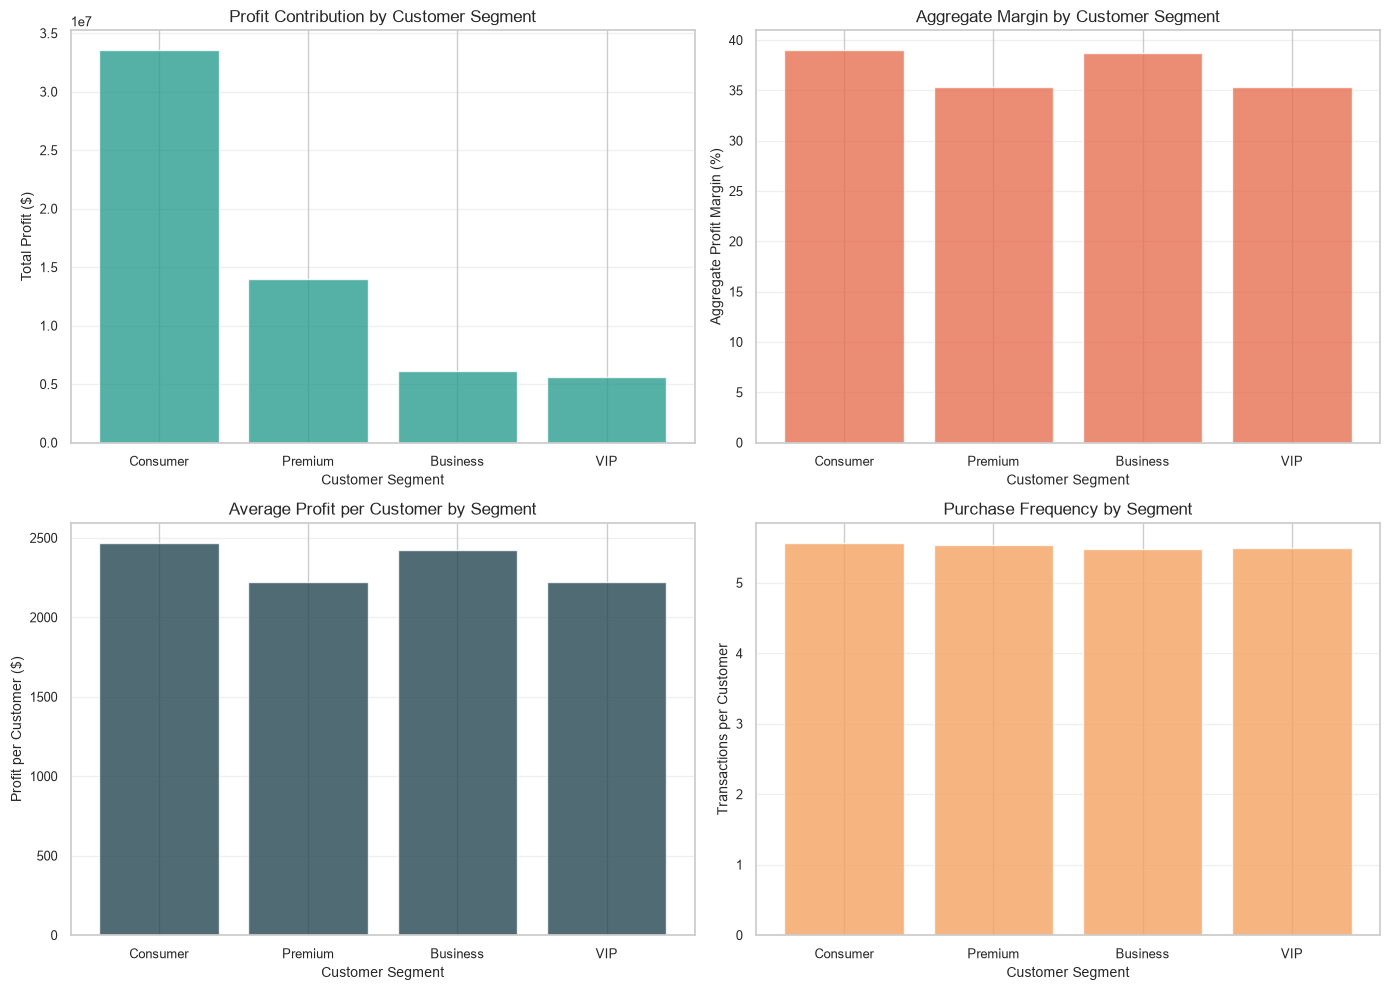

In [27]:
# Visualization: Segment Profitability
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

segments = segment_metrics.index

# Top-left: Profit Contribution by Segment
ax1 = axes[0, 0]
bars = ax1.bar(range(len(segments)), segment_metrics['Total Profit'], alpha=0.8, color='#2A9D8F')
ax1.set_xlabel('Customer Segment')
ax1.set_ylabel('Total Profit ($)')
ax1.set_title('Profit Contribution by Customer Segment')
ax1.set_xticks(range(len(segments)))
ax1.set_xticklabels(segments)
ax1.grid(axis='y', alpha=0.3)

# Top-right: Aggregate Profit Margin by Segment
ax2 = axes[0, 1]
bars = ax2.bar(range(len(segments)), segment_metrics['Aggregate Margin %'], alpha=0.8, color='#E76F51')
ax2.set_xlabel('Customer Segment')
ax2.set_ylabel('Aggregate Profit Margin (%)')
ax2.set_title('Aggregate Margin by Customer Segment')
ax2.set_xticks(range(len(segments)))
ax2.set_xticklabels(segments)
ax2.grid(axis='y', alpha=0.3)

# Bottom-left: Profit per Customer
ax3 = axes[1, 0]
bars = ax3.bar(range(len(segments)), segment_metrics['Profit per Customer'], alpha=0.8, color='#264653')
ax3.set_xlabel('Customer Segment')
ax3.set_ylabel('Profit per Customer ($)')
ax3.set_title('Average Profit per Customer by Segment')
ax3.set_xticks(range(len(segments)))
ax3.set_xticklabels(segments)
ax3.grid(axis='y', alpha=0.3)

# Bottom-right: Transactions per Customer
ax4 = axes[1, 1]
bars = ax4.bar(range(len(segments)), segment_metrics['Transactions per Customer'], alpha=0.8, color='#F4A261')
ax4.set_xlabel('Customer Segment')
ax4.set_ylabel('Transactions per Customer')
ax4.set_title('Purchase Frequency by Segment')
ax4.set_xticks(range(len(segments)))
ax4.set_xticklabels(segments)
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [28]:
# Marketing channel performance by segment
segment_channel_profit = df.groupby(['customer_segment', 'marketing_channel']).agg({
    'profit': 'sum',
    'order_id': 'count'
}).reset_index()

segment_channel_profit['Profit per Transaction'] = (
    segment_channel_profit['profit'] / segment_channel_profit['order_id']
).round(2)

# Pivot for better visualization
pivot_profit = segment_channel_profit.pivot(
    index='marketing_channel', 
    columns='customer_segment', 
    values='Profit per Transaction'
).fillna(0)

print("\nProfit per Transaction: Marketing Channel \u00d7 Customer Segment")
print(pivot_profit)


Profit per Transaction: Marketing Channel × Customer Segment
customer_segment   Business  Consumer  Premium    VIP
marketing_channel                                    
Affiliate            440.57    447.14   413.69 405.31
Direct               449.97    443.99   397.30 399.25
Email Marketing      449.96    445.36   399.43 390.87
Facebook Ads         447.06    439.38   415.11 400.11
Google Ads           442.49    442.57   399.36 400.10
Instagram            440.88    442.27   397.11 406.47
Organic Search       434.04    445.57   398.24 412.30
Referral             434.47    446.73   399.98 410.13
TikTok               442.39    445.49   392.71 413.14
YouTube              434.70    435.64   418.76 395.36


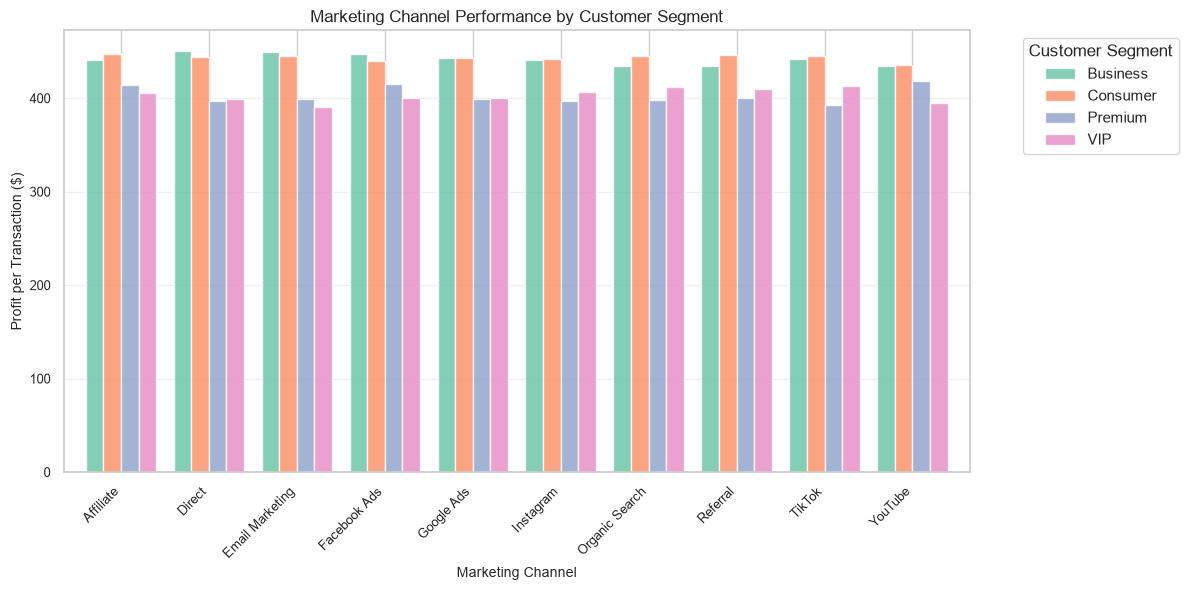

In [29]:
# Visualization: Marketing Channel Segment Profitability
fig, ax = plt.subplots(figsize=(12, 6))

pivot_profit.plot(kind='bar', ax=ax, alpha=0.8, width=0.8)

ax.set_xlabel('Marketing Channel')
ax.set_ylabel('Profit per Transaction ($)')
ax.set_title('Marketing Channel Performance by Customer Segment')
ax.legend(title='Customer Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [30]:
# Repeat customer analysis by segment
# NOTE: is_repeat_customer is unusable as a segmentation source here: it is True for 99.76%
# of transactions, so first-time rows are too few (334) for a segment comparison.
# This cell and the next are kept to document the limitation, not as a finding.

repeat_analysis = df.groupby(['customer_segment', 'is_repeat_customer']).agg({
    'order_id': 'count',
    'profit': 'sum',
    'profit_margin_percentage': 'mean',
    'net_sales': 'mean'
}).round(2)

repeat_analysis.columns = ['Transactions', 'Total Profit', 'Avg Txn Margin %', 'Avg Net Sales']

print("\nRepeat Customer Analysis by Segment (transaction-level):")
print(repeat_analysis)

first_time_n = int((~df['is_repeat_customer']).sum())
print(f"\n[WARNING] is_repeat_customer is True for {df['is_repeat_customer'].mean()*100:.2f}% of transactions.")
print(f"[WARNING] First-time transactions = {first_time_n:,}. Sample too small for a segment comparison;")
print("          do not use is_repeat_customer as a segmentation source without an approved definition.")



Repeat Customer Analysis by Segment (transaction-level):
                                     Transactions  Total Profit  \
customer_segment is_repeat_customer                               
Business         False                         36     15,206.50   
                 True                       13741  6,073,510.27   
Consumer         False                        177     83,166.08   
                 True                       75459 33,473,732.45   
Premium          False                         88     38,622.81   
                 True                       34658 13,913,108.18   
VIP              False                         33     14,211.64   
                 True                       13924  5,620,747.42   

                                     Avg Txn Margin %  Avg Net Sales  
customer_segment is_repeat_customer                                   
Business         False                          45.13       1,032.66  
                 True                           42.38     

In [31]:
# Perbandingan margin: pelanggan pertama kali vs pelanggan berulang per segmen
first_time = df[~df['is_repeat_customer']]
repeat_customers = df[df['is_repeat_customer']]

first_time_margin = first_time.groupby('customer_segment')['profit_margin_percentage'].mean()
repeat_margin = repeat_customers.groupby('customer_segment')['profit_margin_percentage'].mean()

repeat_margin_comparison = pd.DataFrame({
    'First-time Customers': first_time_margin.round(2),
    'Repeat Customers': repeat_margin.round(2),
    'Margin Lift': (repeat_margin - first_time_margin).round(2),
    'First-time N': first_time.groupby('customer_segment').size(),
    'Repeat N': repeat_customers.groupby('customer_segment').size()
})

print("\nProfit Margin: Pelanggan Pertama Kali vs Pelanggan Berulang (transaction-level)")
print(repeat_margin_comparison)
print("\n[WARNING] Selisih negatif di semua segmen, tetapi sampel first-time sangat kecil")
print(f"          ({int((~df['is_repeat_customer']).sum()):,} transaksi total). Perbandingan ini tidak cukup untuk")
print("          menyimpulkan dampak retensi.")



Profit Margin: Pelanggan Pertama Kali vs Pelanggan Berulang (transaction-level)
                  First-time Customers  Repeat Customers  Margin Lift  \
customer_segment                                                        
Business                         45.13             42.38        -2.75   
Consumer                         44.01             42.56        -1.46   
Premium                          38.31             38.66         0.35   
VIP                              40.48             38.55        -1.93   

                  First-time N  Repeat N  
customer_segment                          
Business                    36     13741  
Consumer                   177     75459  
Premium                     88     34658  
VIP                         33     13924  

[WARNING] Selisih negatif di semua segmen, tetapi sampel first-time sangat kecil
          (334 transaksi total). Perbandingan ini tidak cukup untuk
          menyimpulkan dampak retensi.


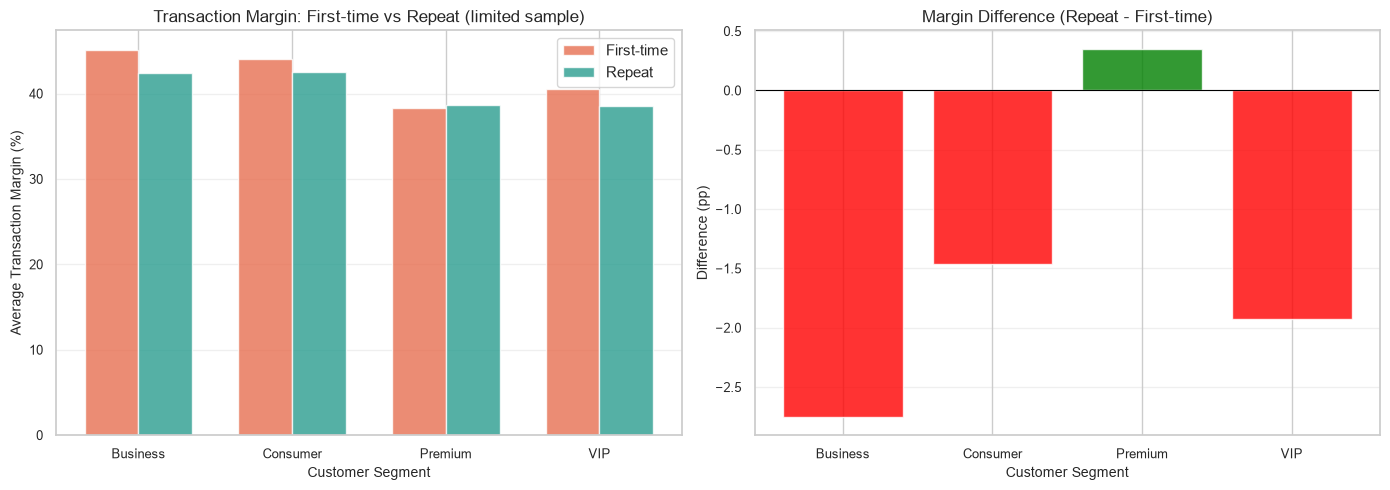

In [32]:
# Visualization: Repeat vs First-time (transaction-level margin; see limitation warning)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

segments_order = repeat_margin_comparison.index

# Left: Margin comparison
ax1 = axes[0]
x_pos = np.arange(len(segments_order))
width = 0.35

bars1 = ax1.bar(x_pos - width/2, repeat_margin_comparison['First-time Customers'],
                width, label='First-time', alpha=0.8, color='#E76F51')
bars2 = ax1.bar(x_pos + width/2, repeat_margin_comparison['Repeat Customers'],
                width, label='Repeat', alpha=0.8, color='#2A9D8F')

ax1.set_xlabel('Customer Segment')
ax1.set_ylabel('Average Transaction Margin (%)')
ax1.set_title('Transaction Margin: First-time vs Repeat (limited sample)')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(segments_order)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Right: Difference (repeat - first-time)
ax2 = axes[1]
colors = ['green' if x > 0 else 'red' for x in repeat_margin_comparison['Margin Lift']]
bars = ax2.bar(range(len(segments_order)), repeat_margin_comparison['Margin Lift'],
               alpha=0.8, color=colors)
ax2.set_xlabel('Customer Segment')
ax2.set_ylabel('Difference (pp)')
ax2.set_title('Margin Difference (Repeat - First-time)')
ax2.set_xticks(range(len(segments_order)))
ax2.set_xticklabels(segments_order)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [33]:
# Repeat purchase metrics: transaction-level vs customer-level
repeat_frequency = df.groupby('customer_segment').agg({
    'is_repeat_customer': ['sum', 'count']
}).round(0)

repeat_frequency.columns = ['Repeat Transactions', 'Total Transactions']
repeat_frequency['Transaction-level Repeat %'] = (
    repeat_frequency['Repeat Transactions'] / repeat_frequency['Total Transactions'] * 100
).round(2)

# Customer-level definition (MVP): a customer with more than one order
orders_per_customer = df.groupby(['customer_segment', 'customer_id']).size().rename('orders')
multi = orders_per_customer[orders_per_customer > 1].groupby('customer_segment').size()
total = orders_per_customer.groupby('customer_segment').size()
repeat_frequency['Customers >1 order'] = multi
repeat_frequency['Total Customers'] = total
repeat_frequency['Customer-level Repeat %'] = (multi / total * 100).round(2)

print("\nRepeat Purchase Metrics by Segment:")
print(repeat_frequency)
print("\n[INFO] Transaction-level Repeat % comes from is_repeat_customer and is not actionable.")
print(f"[INFO] Overall customer-level repeat rate (more than one order): {(df.groupby('customer_id').size() > 1).mean()*100:.2f}%")
print("[INFO] MVP uses the customer-level definition: a customer with more than one order.")



Repeat Purchase Metrics by Segment:
                  Repeat Transactions  Total Transactions  \
customer_segment                                            
Business                        13741               13777   
Consumer                        75459               75636   
Premium                         34658               34746   
VIP                             13924               13957   

                  Transaction-level Repeat %  Customers >1 order  \
customer_segment                                                   
Business                               99.74                2461   
Consumer                               99.77               13302   
Premium                                99.75                6143   
VIP                                    99.76                2481   

                  Total Customers  Customer-level Repeat %  
customer_segment                                            
Business                     2515                    97.85  
Cons

## Fase 6: Sintesis dan Cetak Biru Dashboard

### Ringkasan Temuan Utama

EDA ini mengungkap pola di tiga dimensi strategis.

#### 1. Pola Margin pada Bracket Diskon

Margin menurun secara monoton seiring bertambahnya diskon. Langkah penurunan antar bracket
(rata-rata margin transaksi): 0% ke 1-10% = -3,2 pp, 1-10% ke 11-20% = -4,9 pp, 11-20% ke
21-30% = -7,5 pp, dan 21-30% ke 30%+ = -17,5 pp. Langkah terbesar ada di bracket 30%+, bukan
di 20%.

**Catatan:** ukuran keranjang ikut naik pada diskon tinggi (rata-rata quantity 5,0 pada diskon
0% dan 7,9 pada diskon >30%), sehingga selisih margin antar bracket tidak sepenuhnya efek
diskon. Analisis ini tidak membuktikan sebab-akibat.

**Rekomendasi (perlu validasi):** tinjau kebijakan diskon di bracket tinggi per kategori, dan
uji dampak permintaan sebelum menetapkan batas diskon. Jangan menetapkan angka batas optimal
dari analisis deskriptif ini.

#### 2. Pola Anomali Revenue Tinggi, Margin Rendah

9,31% transaksi (12.855 baris) berada pada kuartil atas revenue dan kuartil bawah margin.
Tingkat anomali antar dimensi relatif sempit (8,92%-9,88%): sales channel 9,15%-9,67%,
region 8,99%-9,48%, dan marketing channel 8,92%-9,88%.

**Rekomendasi (perlu validasi):** audit biaya dan struktur harga pada transaksi berdiskon dalam,
lalu uji hipotesis pada data uji terkontrol sebelum melakukan perubahan kebijakan.

#### 3. Arsitektur Profitabilitas Segmen Pelanggan

Segmen Consumer mendominasi (56,65% total profit) dan memiliki profit per pelanggan tertinggi
($2.470,14). Segmen Premium dan Business tidak memiliki profit per pelanggan tertinggi seperti
yang sering diasumsikan; keduanya di bawah Consumer. Perbedaan margin antar segmen kecil
(margin agregat 35,37%-39,00%).

**Rekomendasi:** prioritaskan program retensi berdasarkan profit per pelanggan, bukan berdasarkan
label tier. Jangan mengklaim efek retensi sebelum definisi pelanggan berulang ditetapkan dan
divalidasi.

### Catatan Keterbatasan (wajib dibaca sebelum memakai angka)

1. **Pembelian berulang belum dapat dianalisis.** `is_repeat_customer` bernilai True untuk 99,76%
   transaksi; hanya 334 transaksi berasal dari pembeli pertama kali. `customer_order_count` dan
   `customer_type` tidak konsisten dengan jumlah transaksi aktual. Perbandingan margin berulang
   vs pertama kali tidak valid dan hanya ditampilkan sebagai keterbatasan.
2. **Definisi pelanggan berulang untuk MVP:** pelanggan dengan lebih dari satu order (tingkat
   pelanggan 97,90%). Tingkat transaksi (99,76%) tidak dipakai sebagai KPI.
3. **Metrik level produk ditunda.** `order_items.csv` belum direkonsiliasi (selisih total +8,61%
   dan 87 pasang `(order_id, product_id)` duplikat), sehingga metrik finansial level produk tidak
   disajikan.
4. **CLV dan ROMI belum tervalidasi.** Keduanya dikeluarkan dari KPI MVP.
5. **Profit diakui pada semua status pesanan**, termasuk Returned dan Cancelled. Lihat Bagian 9
   pada sel "DASHBOARD DATA SPECIFICATIONS": margin agregat Returned dan Cancelled lebih tinggi
   dari rata-rata dataset, jadi interpretasi profit per status memerlukan definisi pengakuan
   pendapatan yang disetujui.
6. **Analisis bersifat deskriptif.** Tidak ada klaim sebab-akibat.

### Cetak Biru Desain Dashboard

#### Tujuan

Dashboard eksekutif satu halaman untuk pemantauan profitabilitas dan dukungan keputusan taktis.

#### Struktur Tata Letak

**Baris Atas - Kartu KPI (4 metrik):**
1. **Total Profit (MTD/QTD):** profit periode berjalan dengan perbandingan YoY
2. **Margin Agregat (%):** total profit / total net sales, dengan rata-rata margin transaksi sebagai metrik pendukung berlabel terpisah
3. **% Transaksi Margin Tinggi (>20%):** 92,0% pada dataset saat ini
4. **Tingkat Pelanggan Berulang:** persentase pelanggan dengan lebih dari satu order (97,90%); bukan tingkat transaksi

**Baris Tengah - Grafik Diagnostik Utama (2 grafik):**

*Panel Kiri:*
- **Grafik:** Kinerja Bracket Diskon (bar chart)
- **Metrik:** margin agregat per bracket (0%, 1-10%, 11-20%, 21-30%, 30%+) dengan rata-rata margin transaksi sebagai pembanding
- **Insight:** memperlihatkan bracket dengan penurunan margin terbesar
- **Interaktivitas:** klik bracket untuk drill-down ke detail transaksi

*Panel Kanan:*
- **Grafik:** Kontribusi Segmen (stacked bar atau treemap)
- **Metrik:** total profit per segmen dengan overlay jumlah transaksi dan profit per pelanggan
- **Insight:** menunjukkan segmen yang mendorong profit aktual vs volume
- **Interaktivitas:** filter segmen menyebar ke komponen lain

**Baris Bawah - Pemantauan Temporal dan Anomali (2 grafik):**

*Panel Kiri:*
- **Grafik:** Tren Profit Bulanan (line chart dengan dual axis)
- **Metrik:** net sales (bar) dan margin agregat (line) per bulan
- **Insight:** pola musiman dan periode kompresi margin
- **Interaktivitas:** hover menampilkan nilai, klik bulan untuk filter

*Panel Kanan:*
- **Grafik:** Heatmap Anomali (grid channel x region)
- **Metrik:** tingkat anomali (%) per kombinasi sales channel dan region
- **Insight:** dimensi operasional yang perlu ditinjau
- **Interaktivitas:** klik sel untuk melihat daftar transaksi

#### Catatan Implementasi Teknis

- **Frekuensi refresh:** update batch harian dari database transaksional
- **Filter:** rentang tanggal, segmen, channel
- **Ambang alert (usulan, dapat dikonfigurasi):** tandai saat margin agregat bulanan turun di bawah persentil ke-10 data historis, atau tingkat anomali bulanan di atas 10%. Angka lama 12% tidak dapat dipakai karena tingkat anomali per dimensi maksimum yang teramati hanya 9,88%.

#### Grafik Prioritas untuk Build Awal

1. **Dampak Bracket Diskon** (Fase 3): visualisasi bracket dengan dua basis margin
2. **Profitabilitas Segmen Pelanggan** (Fase 5): kinerja segmen empat panel
3. **Tren Bulanan** (Fase 2): grafik musiman bulanan dual-axis
4. **Anomali per Dimensi Operasional** (Fase 4): distribusi anomali tiga panel
5. **Musiman Bulan per Tahun** (Fase 2): heatmap net sales dan margin per bulan per tahun


In [34]:
# Generate final summary statistics for dashboard specification
print("DASHBOARD DATA SPECIFICATIONS")

print("\n1. KPI Metrics (Current Dataset):")
print(f"   Total Net Sales: ${df['net_sales'].sum():,.2f}")
print(f"   Total Profit: ${df['profit'].sum():,.2f}")
print(f"   Aggregate Profit Margin (primary): {df['profit'].sum() / df['net_sales'].sum() * 100:.2f}%")
print(f"   Average Transaction Margin (secondary): {df['profit_margin_percentage'].mean():.2f}%")
print(f"   Orders: {len(df):,}")
print(f"   Transactions with margin > 20%: {(df['profit_margin_percentage'] > 20).sum():,} ({(df['profit_margin_percentage'] > 20).mean()*100:.1f}%)")
print(f"   Repeat Customer Rate (customer-level, >1 order): {(df.groupby('customer_id').size() > 1).mean()*100:.2f}%")

print("\n2. Discount Bracket Distribution (both margins):")
print(discount_analysis[['Transactions', 'Total Net Sales', 'Total Profit',
                         'Avg Txn Margin %', 'Aggregate Margin %', 'Profit per Transaction']])

print("\n3. Customer Segments by Profit:")
print(segment_metrics[['Transactions', 'Unique Customers', 'Total Net Sales', 'Total Profit',
                       'Aggregate Margin %', 'Avg Txn Margin %', 'Profit per Customer']])

print("\n4. Anomaly Rates by Channel (inclusive rule):")
anomaly_by_channel = (df.groupby('sales_channel')['is_anomaly'].mean() * 100).round(2).rename('Anomaly %')
print(anomaly_by_channel.sort_values(ascending=False))

print("\n5. Monthly Seasonality (both margins):")
monthly_baseline = df.groupby('order_month').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum',
    'profit_margin_percentage': 'mean'
}).round(2)
monthly_baseline.columns = ['Transactions', 'Net Sales', 'Profit', 'Avg Txn Margin %']
monthly_baseline['Aggregate Margin %'] = (monthly_baseline['Profit'] / monthly_baseline['Net Sales'] * 100).round(2)
print(monthly_baseline)

print("\n6. Annual Performance with YoY:")
print(yearly_metrics)

print("\n7. Net Sales per Month per Year ($M):")
month_year_sales = df.pivot_table(index='order_year', columns='order_month',
                                  values='net_sales', aggfunc='sum') / 1e6
print(month_year_sales.round(2))

print("\n8. Aggregate Margin per Month per Year (%):")
month_year_margin = (df.pivot_table(index='order_year', columns='order_month', values='profit', aggfunc='sum')
                     / df.pivot_table(index='order_year', columns='order_month', values='net_sales', aggfunc='sum') * 100)
print(month_year_margin.round(2))

print("\n9. Validation Checks (customer count, CLV, order status):")
unique_customers = df['customer_id'].nunique()
clv_per_customer = df.groupby('customer_id')['customer_lifetime_value'].first()
profit_per_customer = df.groupby('customer_id')['profit'].sum()
print(f"   Unique customers in the fact table: {unique_customers:,}")
print(f"   Realised profit per customer (mean): ${profit_per_customer.mean():,.2f}")
print(f"   Average CLV per customer (unvalidated field): ${clv_per_customer.mean():,.2f}")
print(f"   Average transaction CLV (unvalidated field): ${df['customer_lifetime_value'].mean():,.2f}")
print(f"   Share of customers with CLV > own realised profit: {(clv_per_customer > profit_per_customer).mean()*100:.2f}%")
status_agg = df.groupby('order_status').agg({
    'order_id': 'count',
    'net_sales': 'sum',
    'profit': 'sum'
}).rename(columns={'order_id': 'Transactions', 'net_sales': 'Net Sales', 'profit': 'Profit'})
status_agg['Aggregate Margin %'] = (status_agg['Profit'] / status_agg['Net Sales'] * 100).round(2)
print("\n   Profit margin by order status (aggregate):")
print(status_agg.round(2))

print("END OF EXPLORATORY DATA ANALYSIS")
print(f"Total transactions analyzed: {len(df):,}")
print(f"Date range: {df['order_date'].min().date()} to {df['order_date'].max().date()}")
print("Key insights documented in Phase 6 synthesis")
print("\nNext steps:")
print("  1. Review discount policy based on Phase 3 findings (validate demand impact first)")
print("  2. Investigate anomaly drivers identified in Phase 4")
print("  3. Implement dashboard blueprint from Phase 6")
print("  4. Establish monitoring cadence for KPI tracking")


DASHBOARD DATA SPECIFICATIONS

1. KPI Metrics (Current Dataset):
   Total Net Sales: $157,143,214.06
   Total Profit: $59,232,305.35
   Aggregate Profit Margin (primary): 37.69%
   Average Transaction Margin (secondary): 41.16%
   Orders: 138,116
   Transactions with margin > 20%: 127,077 (92.0%)
   Repeat Customer Rate (customer-level, >1 order): 97.90%

2. Discount Bracket Distribution (both margins):
                  Transactions  Total Net Sales  Total Profit  \
discount_bracket                                                
0% (No Discount)         17864    21,770,139.34 10,538,011.45   
1-10%                    35031    39,340,499.03 17,601,245.35   
11-20%                   49198    52,820,114.92 21,062,207.54   
21-30%                   17729    21,188,389.22  6,689,904.26   
30%+                     18294    22,024,071.55  3,340,936.75   

                  Avg Txn Margin %  Aggregate Margin %  Profit per Transaction  
discount_bracket                                        